In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [ ]:
df=pd.read_csv(r"/content/diabetes_patients_10000_full.csv")
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [ ]:
df=df.drop('Patient_ID',axis=1)
df.head()

,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                9986 non-null   float64
 1   Gender             9960 non-null   object 
 2   Blood_Sugar_Level  9947 non-null   float64
 3   Creatinine         9944 non-null   float64
 4   BMI                9949 non-null   float64
 5   Urea               9949 non-null   float64
 6   Cholesterol        9968 non-null   float64
 7   HbA1c              10000 non-null  float64
 8   Class              10000 non-null  object 
dtypes: float64(7), object(2)
memory usage: 703.3+ KB


In [ ]:
df.shape

(10000, 9)

In [ ]:
df.isna().sum()

,0
Age,14
Gender,40
Blood_Sugar_Level,53
Creatinine,56
BMI,51
Urea,51
Cholesterol,32
HbA1c,0
Class,0


In [ ]:
df.isnull().sum().sum()

np.int64(297)

In [ ]:
df = df.dropna()

In [ ]:
df.describe()

,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,9932.000000,9932.000000,9932.000000,9932.000000,9932.000000,9932.000000,9932.000000
mean,49.951269,169.241643,1.100316,26.748278,35.127467,225.325816,7.502638
std,17.635345,46.066343,0.286962,4.788006,11.829405,43.793351,1.744035
min,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(9932, 9)

In [ ]:
df.isna().sum()

,0
Age,0
Gender,0
Blood_Sugar_Level,0
Creatinine,0
BMI,0
Urea,0
Cholesterol,0
HbA1c,0
Class,0


In [ ]:
x=df.drop('Class',axis=1)
y=df['Class']

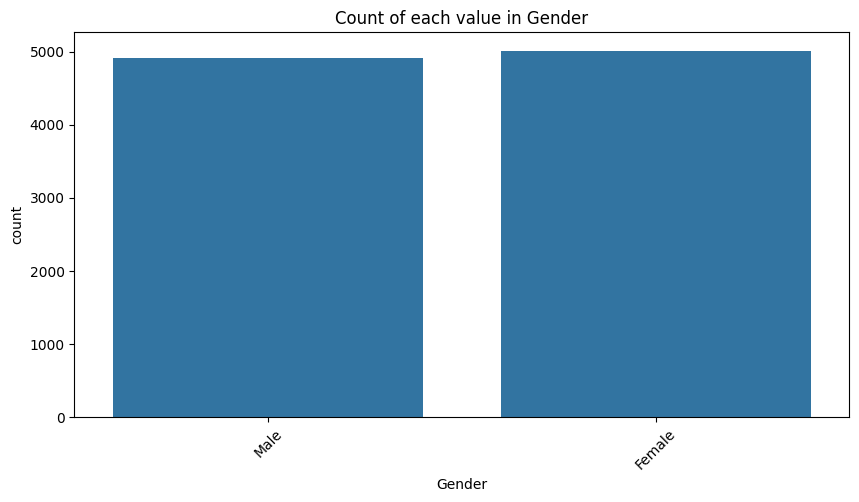

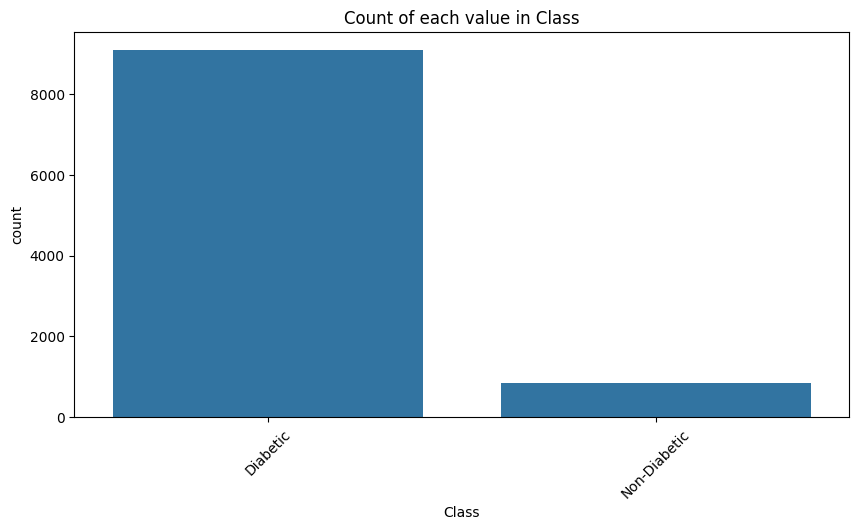

In [ ]:
cat=df.select_dtypes(include='object')

for col in cat:
    plt.figure(figsize=(10, 5))

    sns.countplot(data=df, x=col)

    plt.title(f'Count of each value in {col}')
    plt.xticks(rotation=45)
    plt.show()

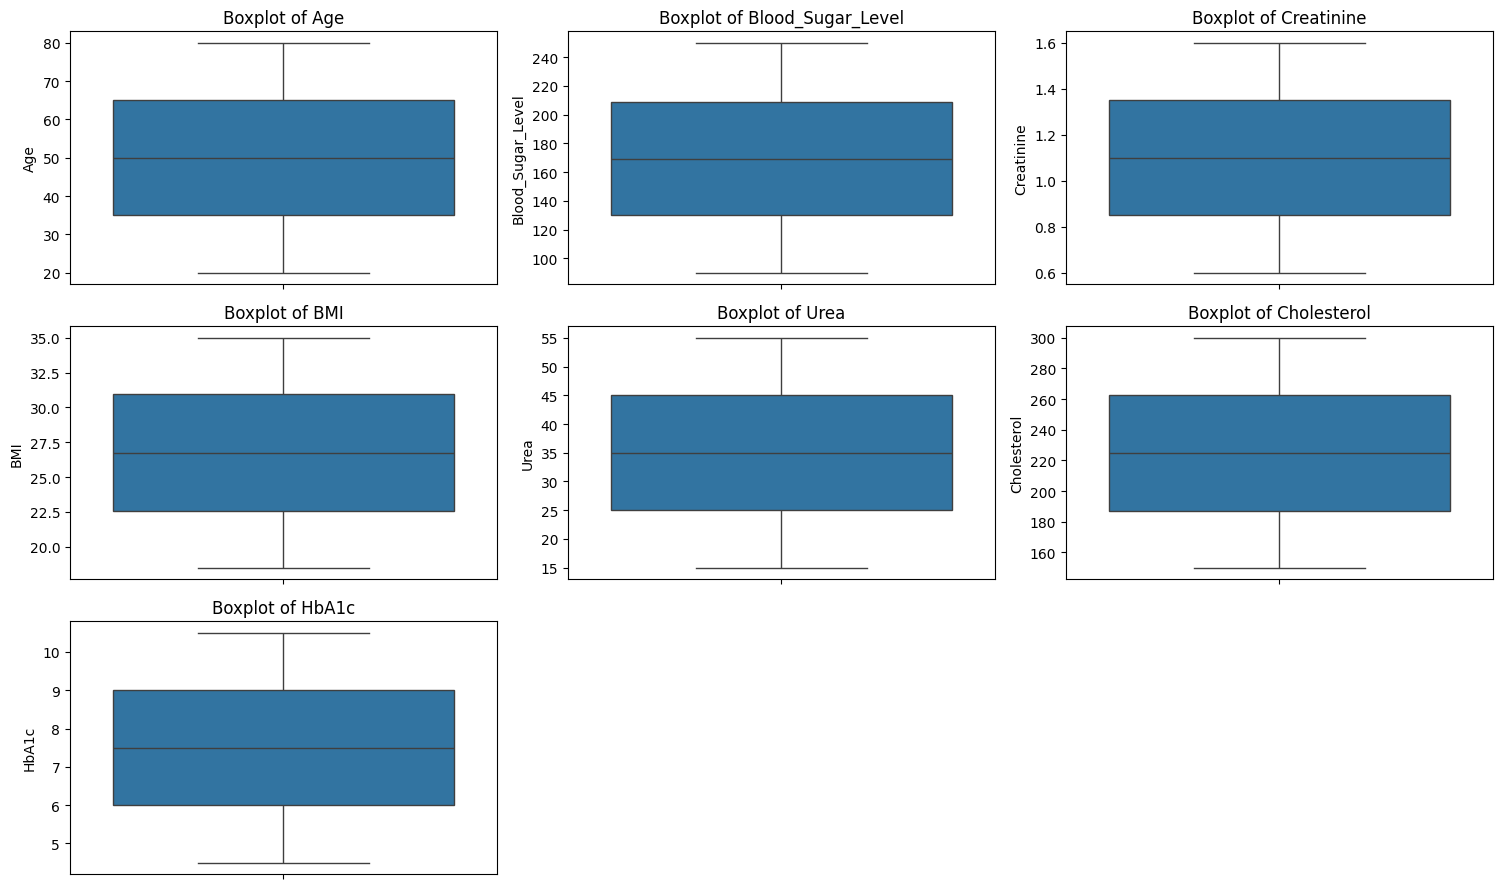

In [ ]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
num_plots = len(numeric_cols)
cols_grid = 3
rows_grid = (num_plots + cols_grid - 1) // cols_grid

plt.figure(figsize=(15, 3 * rows_grid))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows_grid, cols_grid, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

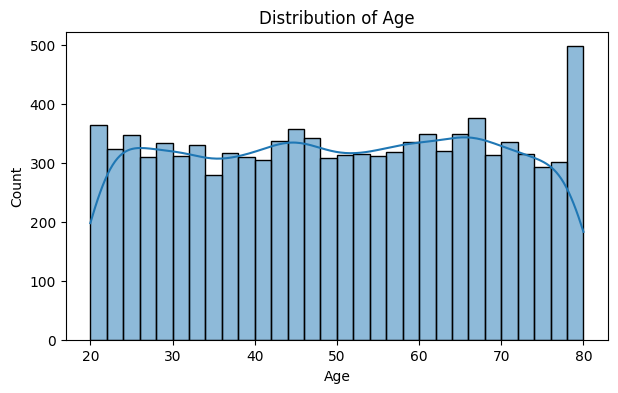

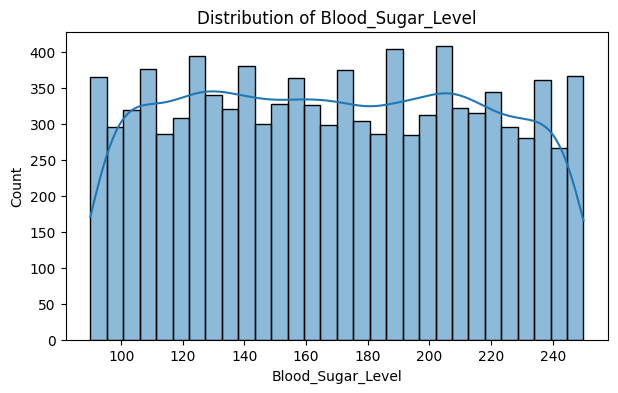

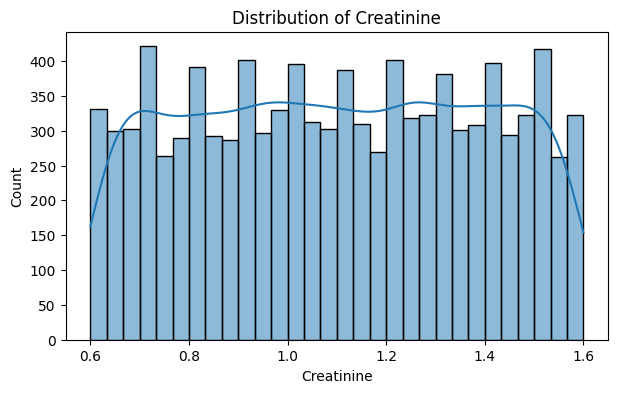

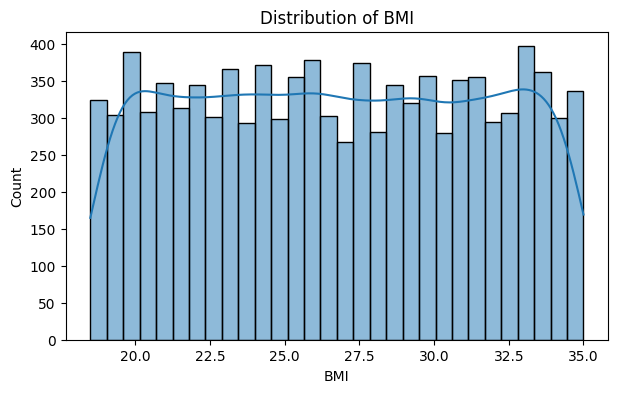

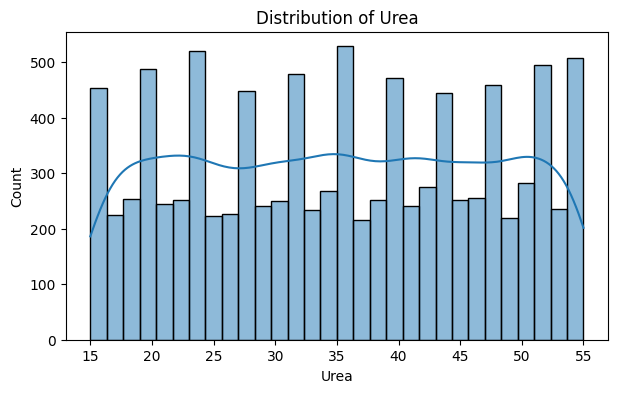

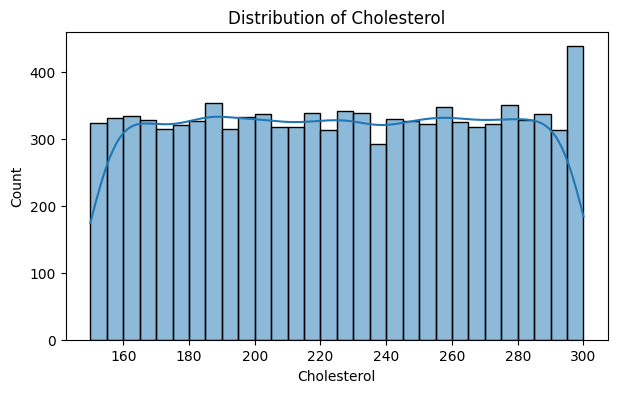

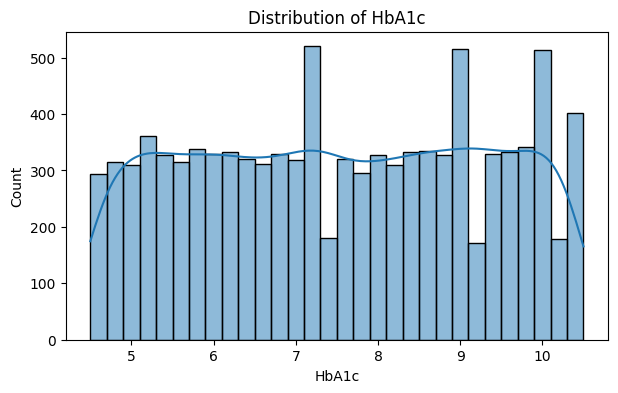

In [ ]:


for col in numeric_cols:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.show()


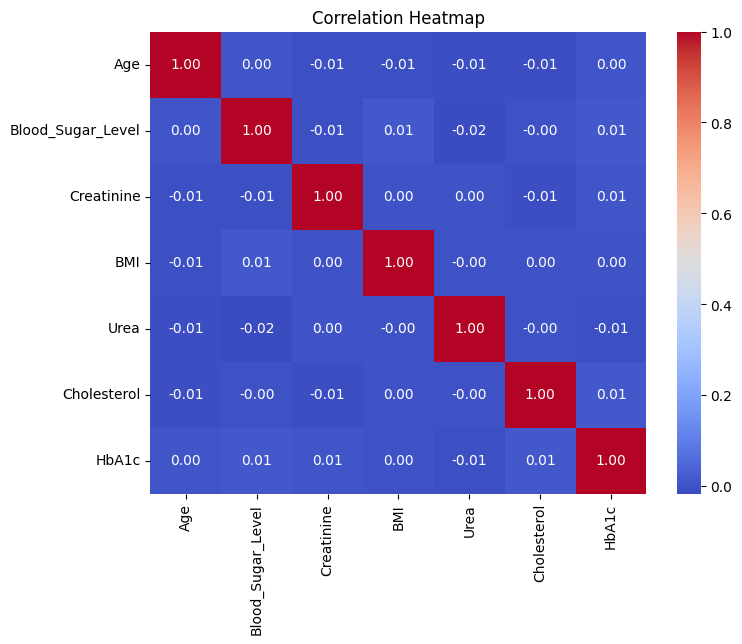

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
for col in numeric_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers = df[
      (df[col] < lower) |
      (df[col] > upper)
  ]


  print("Number of Outliers:", len(outliers))

Number of Outliers: 0
Number of Outliers: 0
Number of Outliers: 0
Number of Outliers: 0
Number of Outliers: 0
Number of Outliers: 0
Number of Outliers: 0


In [ ]:
x=df.drop('Class',axis=1)
y=df['Class']

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [ ]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(7945, 8)
(1987, 8)
(7945,)
(1987,)


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
cat = x_train.select_dtypes(include='object')
for col in cat:
    combined_series = pd.concat([x_train[col], x_test[col]]).astype(str)
    le.fit(combined_series)
    x_train[col] = le.transform(x_train[col].astype(str))
    x_test[col] = le.transform(x_test[col].astype(str))
    y_train = le.fit_transform(y_train)
    y_test = le.transform(y_test)


In [ ]:
from sklearn.preprocessing import StandardScaler
scalar=StandardScaler()
for i in x_train.select_dtypes(include='number'):
    x_train[[i]] = scalar.fit_transform(x_train[[i]])
    x_test[[i]] = scalar.transform(x_test[[i]])


In [ ]:
pip install xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 52.3 MB/s  0:00:01


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [ ]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

In [ ]:
from sklearn.model_selection import cross_validate, KFold
import pandas as pd

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1'
}

cv_results = {}

# We will perform 5-fold cross-validation on our top-performing models
selected_models = {
    "LightGBM": models["LightGBM"],
    "CatBoost": models["CatBoost"],
    "XGBoost": models["XGBoost"],
    "Random Forest": models["Random Forest"]
}

for name, model in selected_models.items():
    cv = cross_validate(model, x_train, y_train, cv=kfold, scoring=scoring, return_train_score=True, n_jobs=-1)
    cv_results[name] = {
        'Train Accuracy': cv['train_Accuracy'].mean(),
        'CV Accuracy': cv['test_Accuracy'].mean(),
        'CV Precision': cv['test_Precision'].mean(),
        'CV Recall': cv['test_Recall'].mean(),
        'CV F1 Score': cv['test_F1'].mean(),
        'Fit time (s)': cv['fit_time'].mean(),
    }
    print(f"{name:15s} -> CV Accuracy: {cv_results[name]['CV Accuracy']:.4f} | CV F1: {cv_results[name]['CV F1 Score']:.4f}")

# Display as DataFrame
cv_results_df = pd.DataFrame(cv_results).T
display(cv_results_df)

LightGBM        -> CV Accuracy: 1.0000 | CV F1: 1.0000
CatBoost        -> CV Accuracy: 1.0000 | CV F1: 1.0000
XGBoost         -> CV Accuracy: 1.0000 | CV F1: 1.0000
Random Forest   -> CV Accuracy: 1.0000 | CV F1: 1.0000


,Train Accuracy,CV Accuracy,CV Precision,CV Recall,CV F1 Score,Fit time (s)
LightGBM,1.0,1.0,1.0,1.0,1.0,0.238234
CatBoost,1.0,1.0,1.0,1.0,1.0,7.106002
XGBoost,1.0,1.0,1.0,1.0,1.0,0.541867
Random Forest,1.0,1.0,1.0,1.0,1.0,0.710493


In [ ]:
from tqdm import tqdm

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[1810   30]
 [  40  107]]


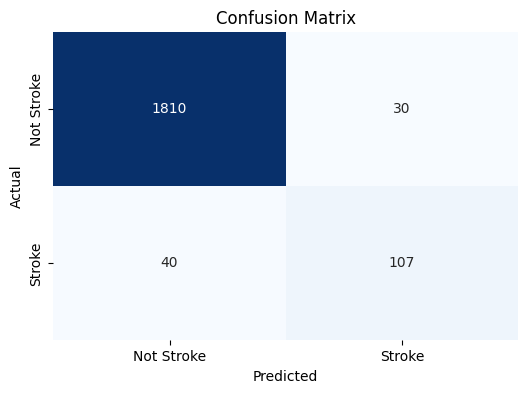


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.98      0.98      0.98      1840
      Stroke       0.78      0.73      0.75       147

    accuracy                           0.96      1987
   macro avg       0.88      0.86      0.87      1987
weighted avg       0.96      0.96      0.96      1987

ROC-AUC: 0.9893559597752144


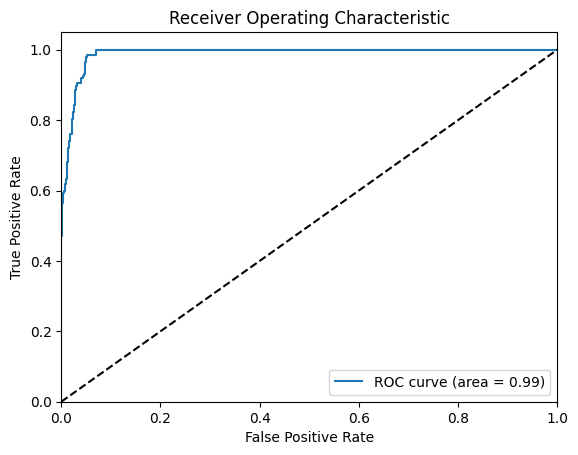

PR AUC: 0.8890863628985303


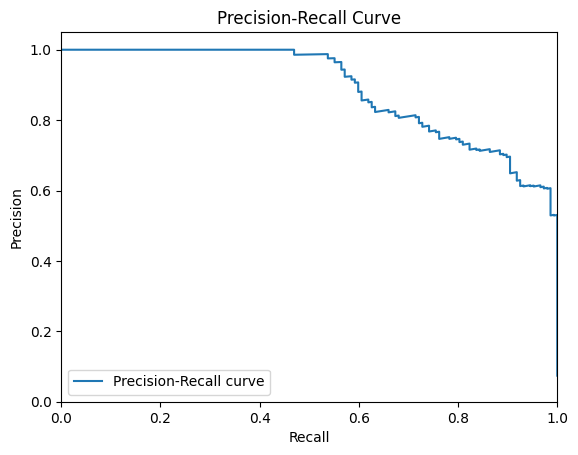

  8%|▊         | 1/13 [00:00<00:04,  2.60it/s]


Confusion Matrix:
 [[1810   30]
 [  57   90]]


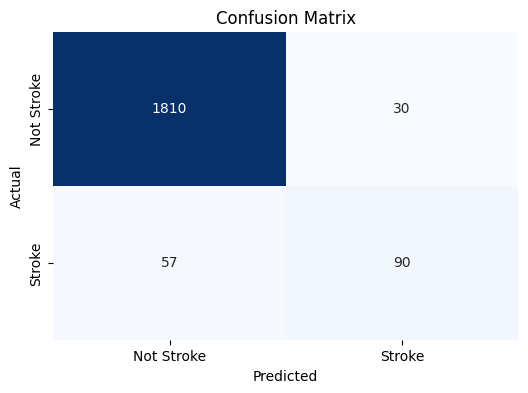


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.97      0.98      0.98      1840
      Stroke       0.75      0.61      0.67       147

    accuracy                           0.96      1987
   macro avg       0.86      0.80      0.83      1987
weighted avg       0.95      0.96      0.95      1987

ROC-AUC: 0.9573425022182787


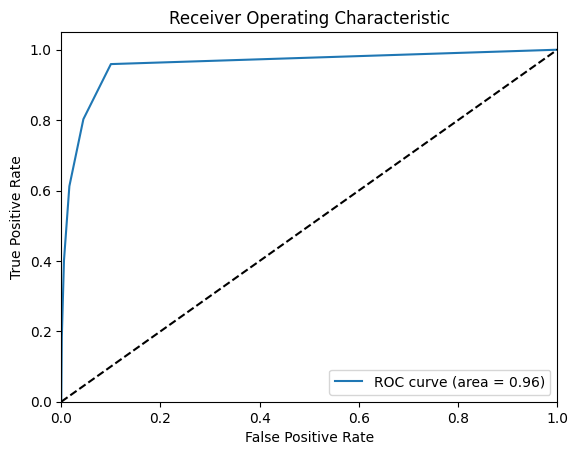

PR AUC: 0.6985890929773877


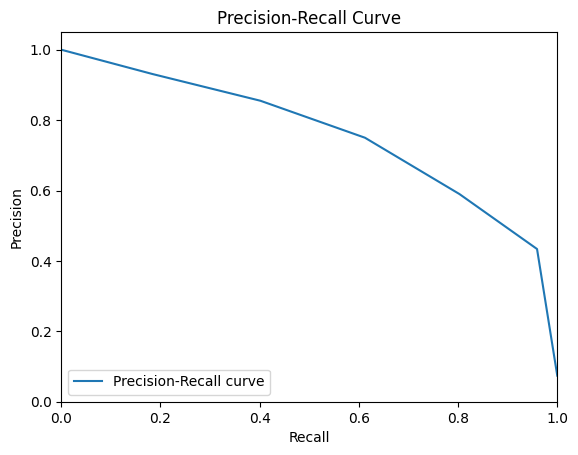

 15%|█▌        | 2/13 [00:01<00:06,  1.72it/s]


Confusion Matrix:
 [[1816   24]
 [  30  117]]


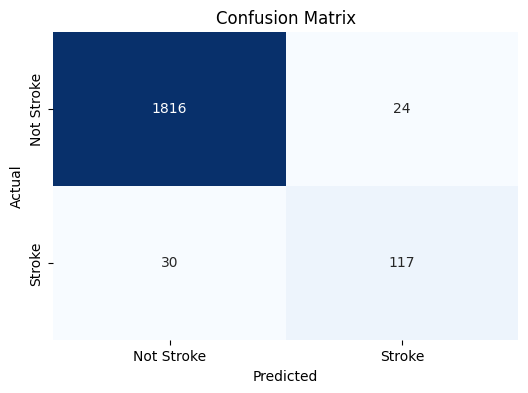


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.98      0.99      0.99      1840
      Stroke       0.83      0.80      0.81       147

    accuracy                           0.97      1987
   macro avg       0.91      0.89      0.90      1987
weighted avg       0.97      0.97      0.97      1987

ROC-AUC: 0.9935374149659865


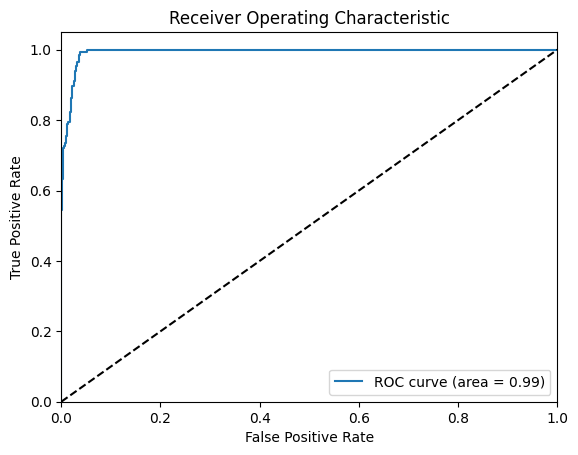

PR AUC: 0.929311209744771


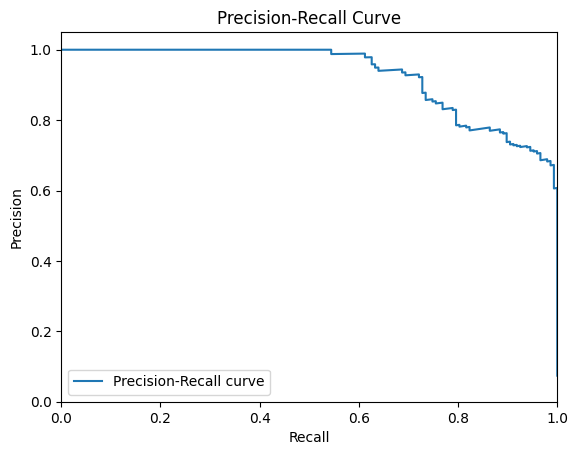

 23%|██▎       | 3/13 [00:03<00:12,  1.21s/it]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


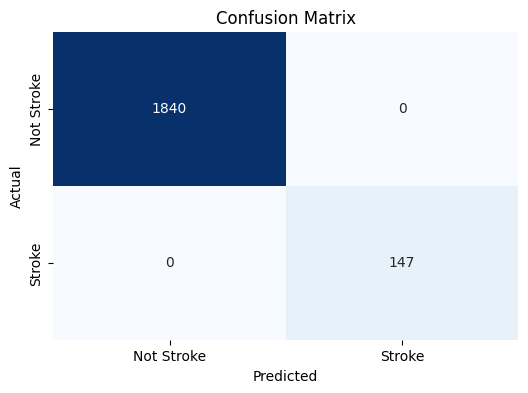


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


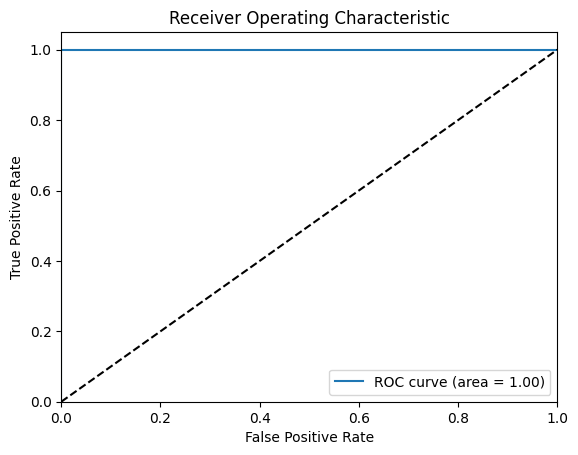

PR AUC: 1.0


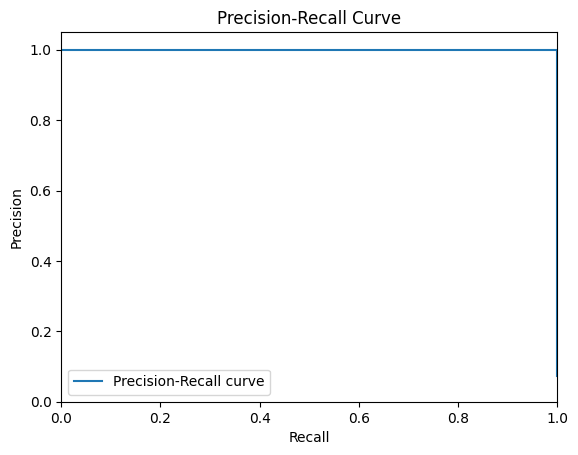

 31%|███       | 4/13 [00:03<00:07,  1.16it/s]


Confusion Matrix:
 [[1840    0]
 [  16  131]]


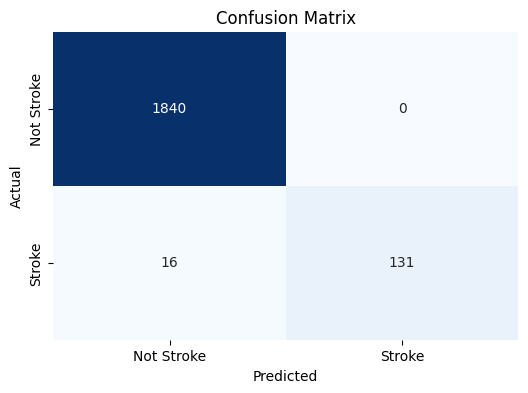


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      1.00      1.00      1840
      Stroke       1.00      0.89      0.94       147

    accuracy                           0.99      1987
   macro avg       1.00      0.95      0.97      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: 0.9992420881396037


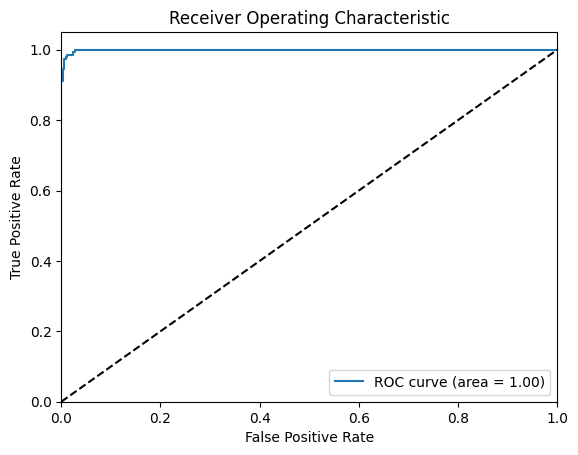

PR AUC: 0.991784244976962


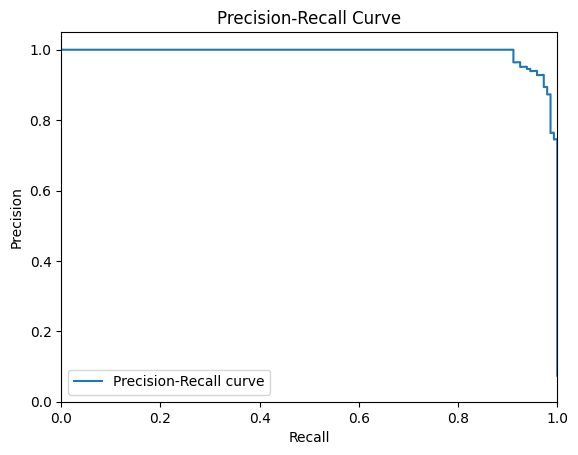

 38%|███▊      | 5/13 [00:03<00:05,  1.47it/s]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


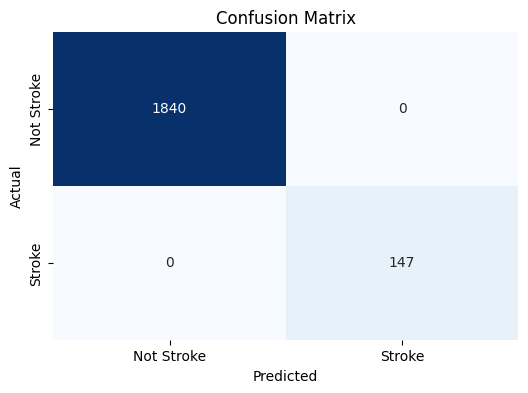


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


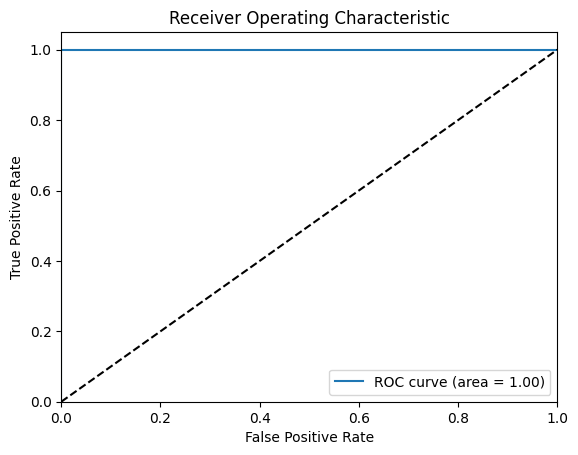

PR AUC: 1.0


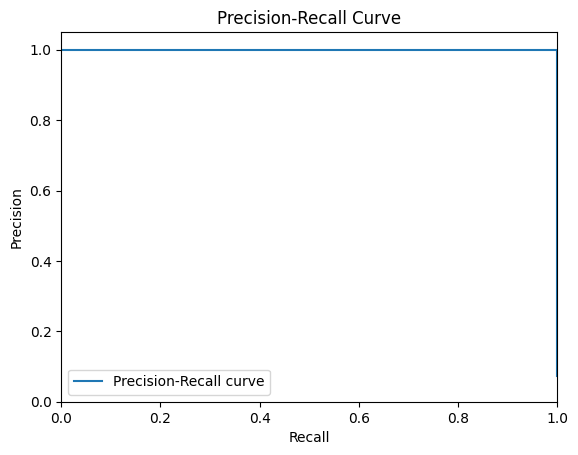

 46%|████▌     | 6/13 [00:04<00:04,  1.41it/s]


Confusion Matrix:
 [[1838    2]
 [  24  123]]


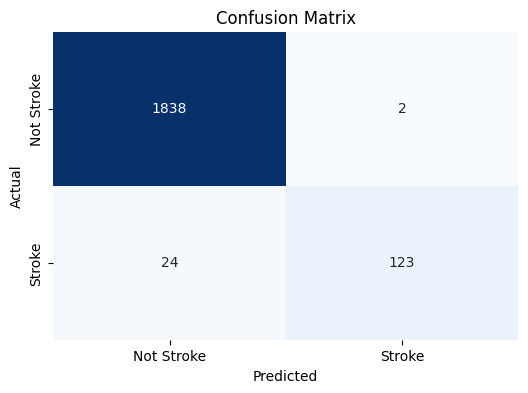


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      1.00      0.99      1840
      Stroke       0.98      0.84      0.90       147

    accuracy                           0.99      1987
   macro avg       0.99      0.92      0.95      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: 0.9993104850635907


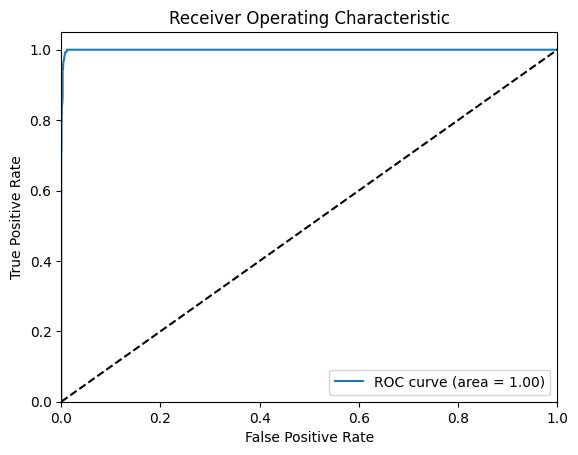

PR AUC: 0.9904857996155205


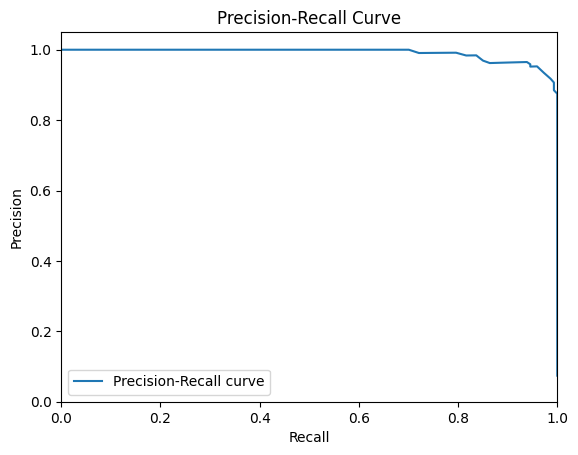

 54%|█████▍    | 7/13 [00:05<00:05,  1.19it/s]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


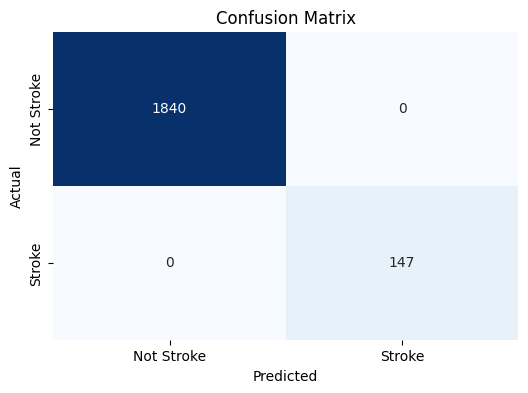


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


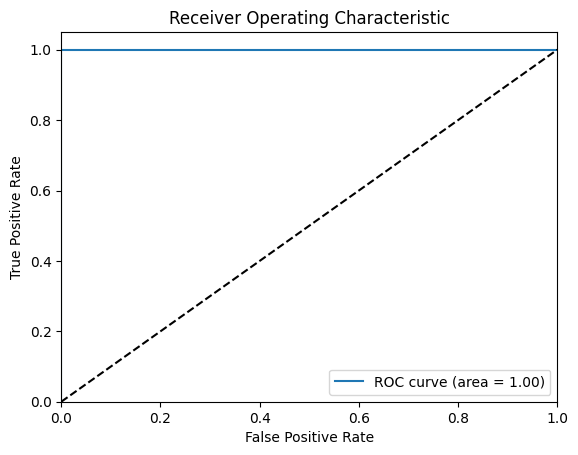

PR AUC: 1.0


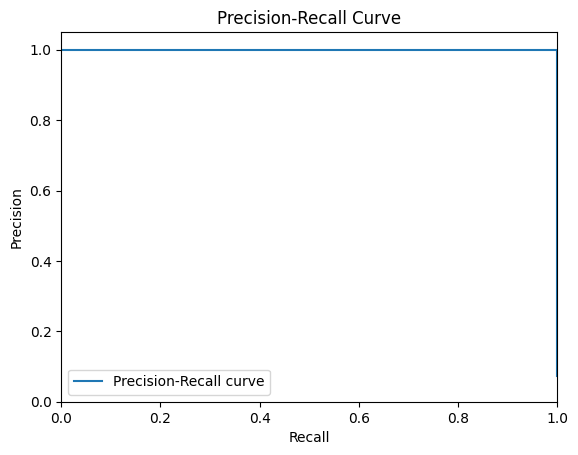

 62%|██████▏   | 8/13 [00:06<00:04,  1.12it/s]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


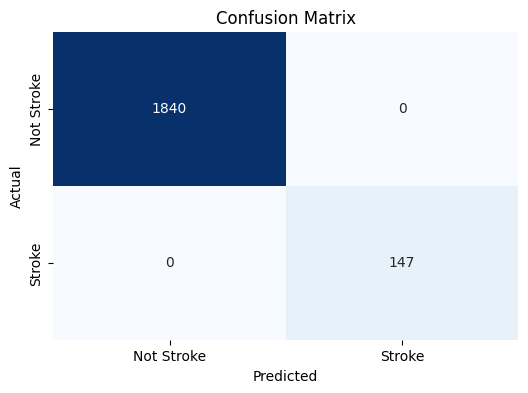


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


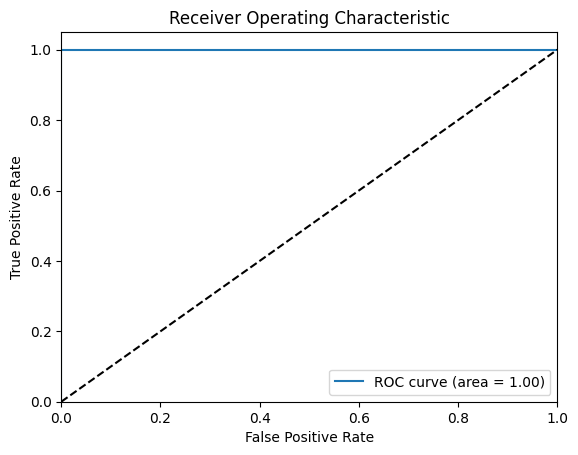

PR AUC: 1.0


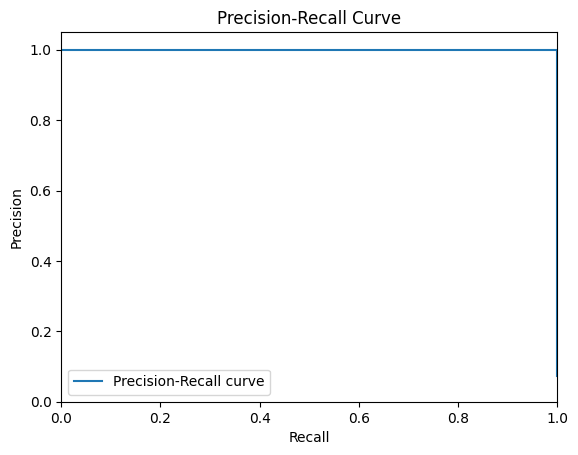

 69%|██████▉   | 9/13 [00:07<00:04,  1.00s/it]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


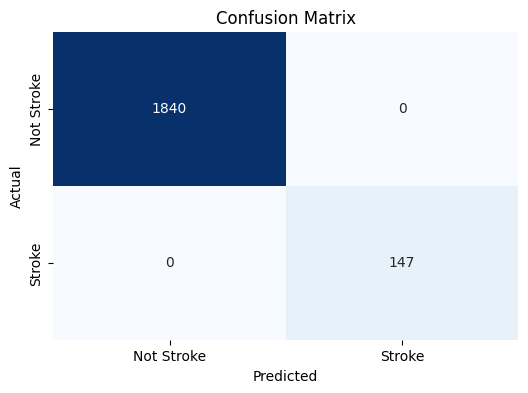


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


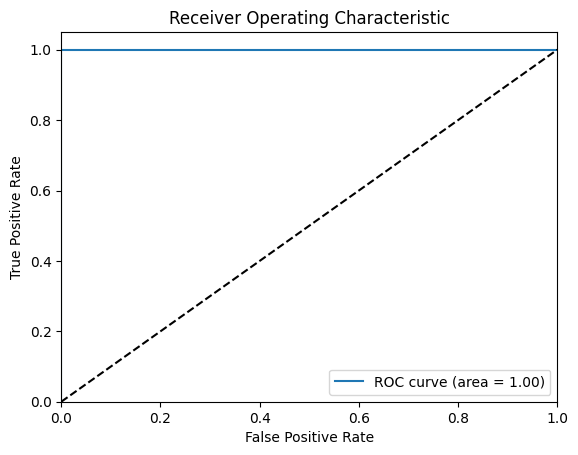

PR AUC: 1.0


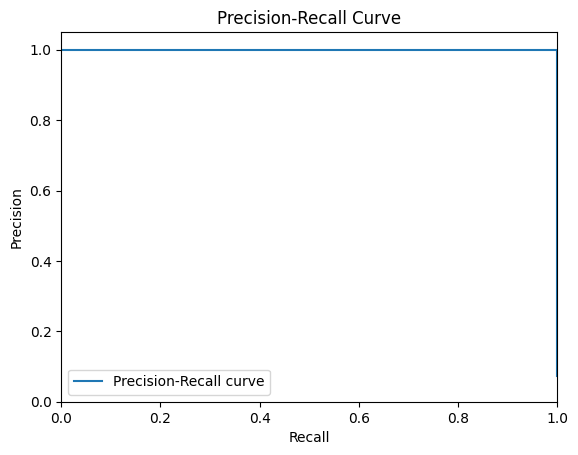

 77%|███████▋  | 10/13 [00:08<00:02,  1.17it/s]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:05:52] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


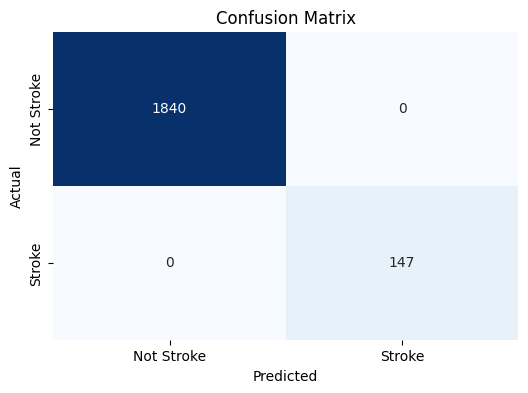


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


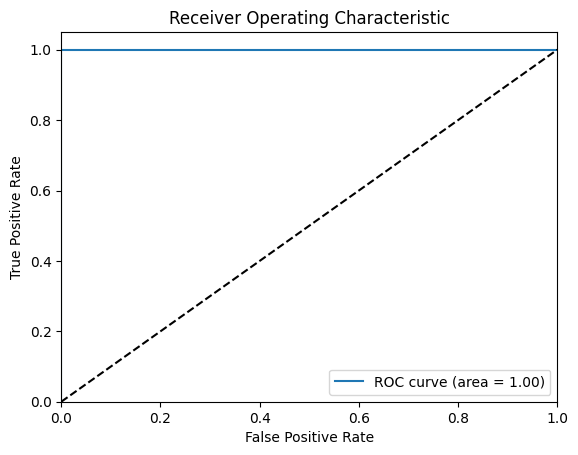

PR AUC: 1.0


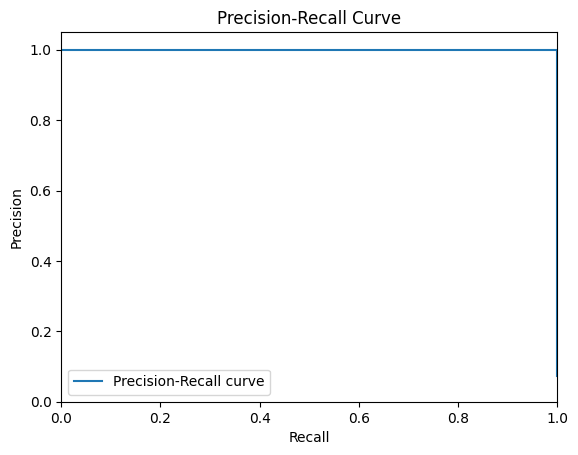

 85%|████████▍ | 11/13 [00:09<00:01,  1.26it/s]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


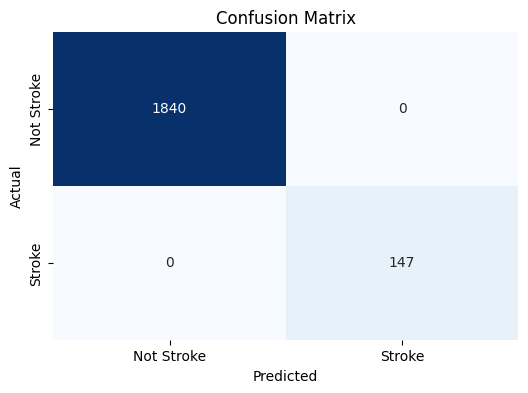


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


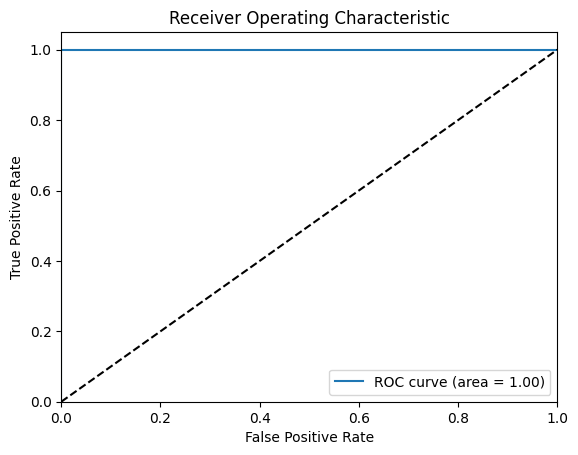

PR AUC: 1.0


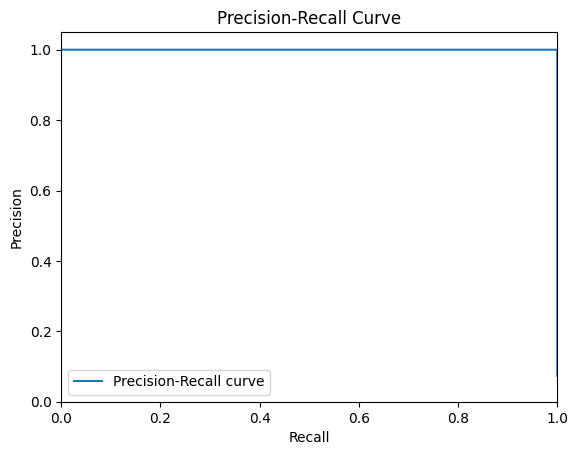

 92%|█████████▏| 12/13 [00:12<00:01,  1.52s/it]

[LightGBM] [Info] Number of positive: 702, number of negative: 7243
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000203 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 752
[LightGBM] [Info] Number of data points in the train set: 7945, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.088357 -> initscore=-2.333857
[LightGBM] [Info] Start training from score -2.333857
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

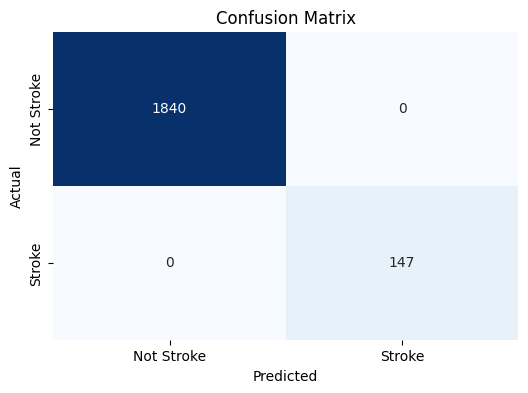


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


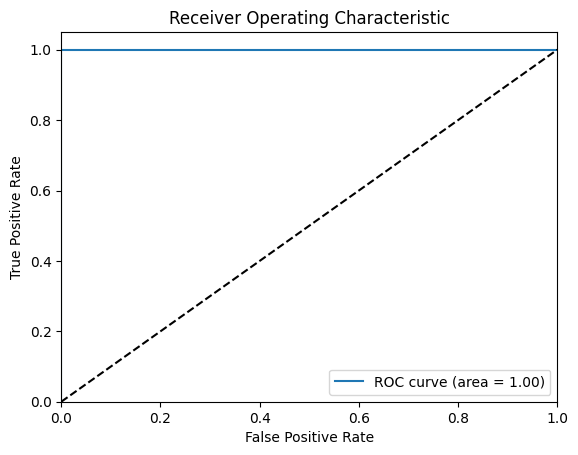

PR AUC: 1.0


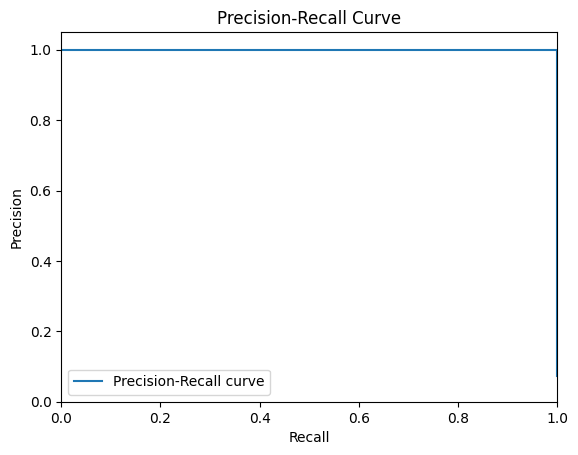

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[1810   30]
 [  40  107]]


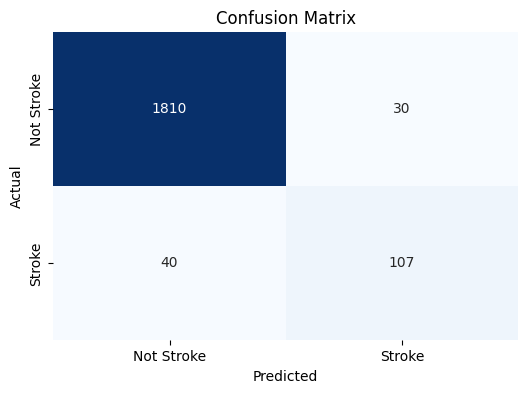


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.98      0.98      0.98      1840
      Stroke       0.78      0.73      0.75       147

    accuracy                           0.96      1987
   macro avg       0.88      0.86      0.87      1987
weighted avg       0.96      0.96      0.96      1987

ROC-AUC: 0.9893559597752144


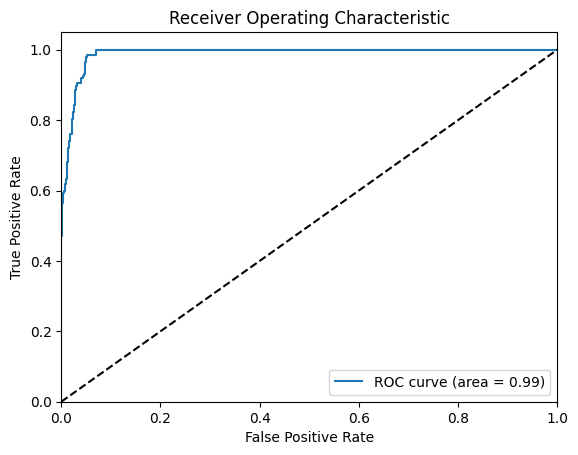

PR AUC: 0.8890863628985303


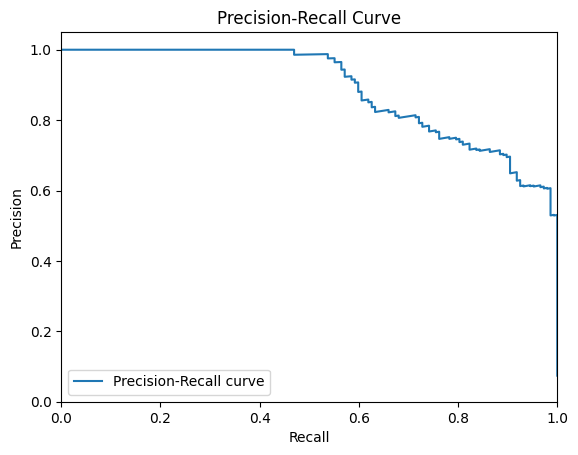

  8%|▊         | 1/13 [00:00<00:05,  2.29it/s]


Confusion Matrix:
 [[1810   30]
 [  57   90]]


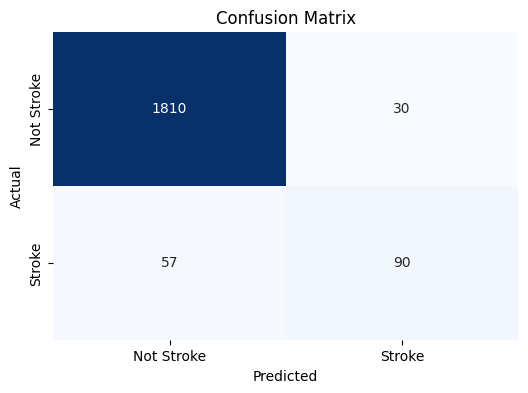


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.97      0.98      0.98      1840
      Stroke       0.75      0.61      0.67       147

    accuracy                           0.96      1987
   macro avg       0.86      0.80      0.83      1987
weighted avg       0.95      0.96      0.95      1987

ROC-AUC: 0.9573425022182787


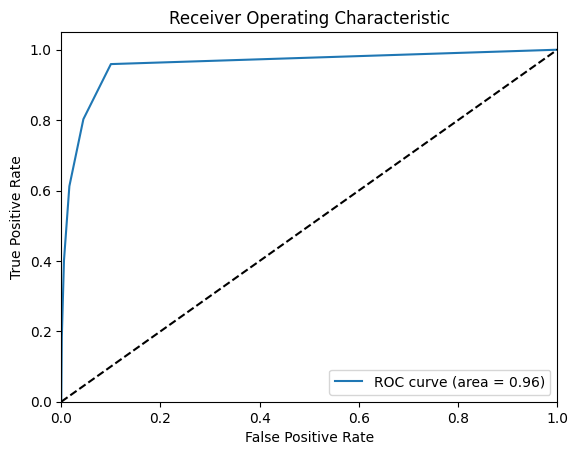

PR AUC: 0.6985890929773877


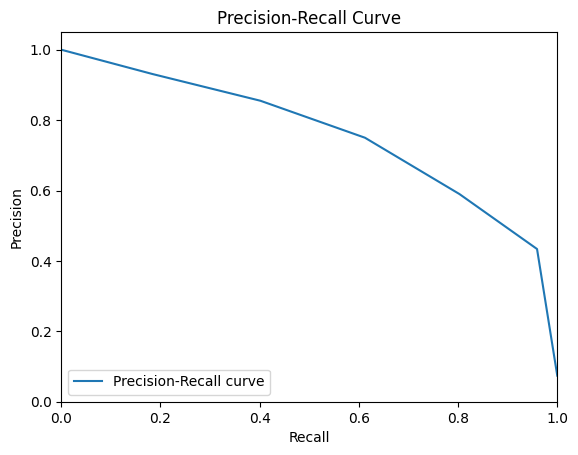

 15%|█▌        | 2/13 [00:01<00:06,  1.61it/s]


Confusion Matrix:
 [[1816   24]
 [  30  117]]


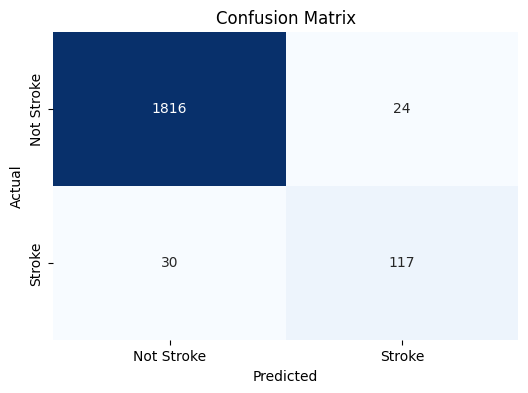


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.98      0.99      0.99      1840
      Stroke       0.83      0.80      0.81       147

    accuracy                           0.97      1987
   macro avg       0.91      0.89      0.90      1987
weighted avg       0.97      0.97      0.97      1987

ROC-AUC: 0.9935374149659865


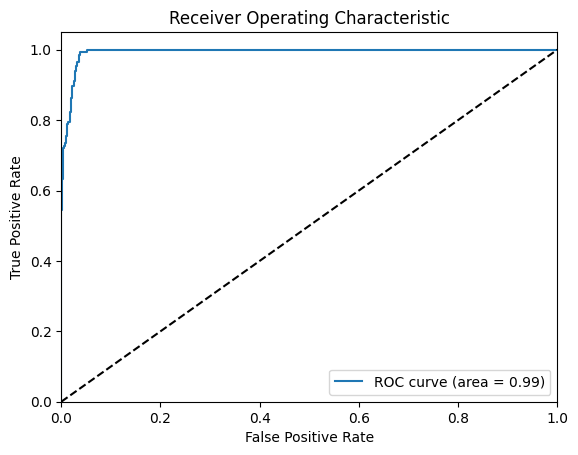

PR AUC: 0.929311209744771


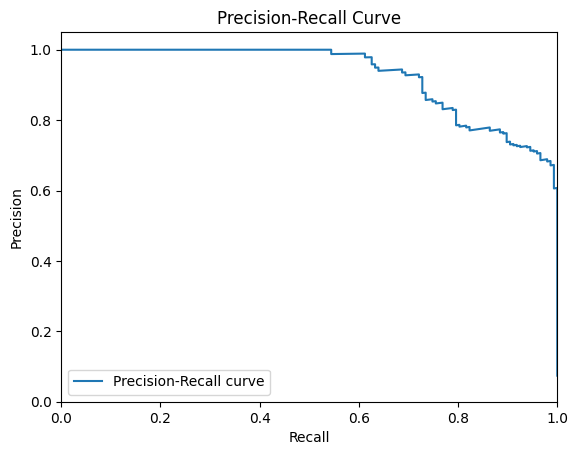

 23%|██▎       | 3/13 [00:03<00:12,  1.26s/it]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


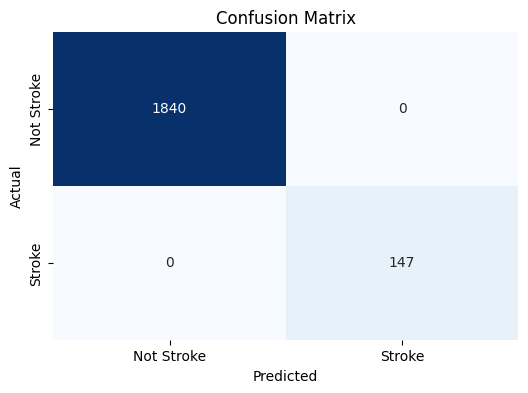


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


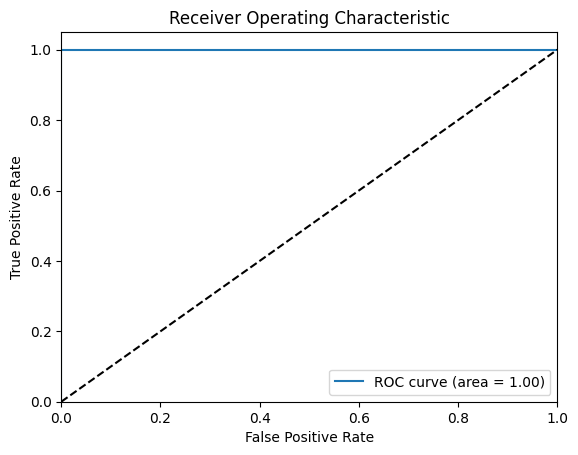

PR AUC: 1.0


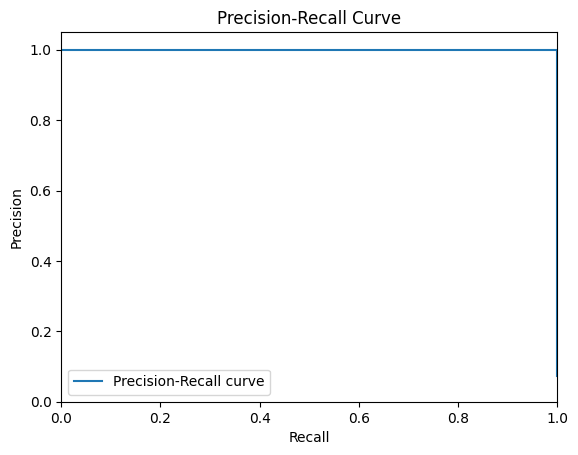

 31%|███       | 4/13 [00:03<00:08,  1.08it/s]


Confusion Matrix:
 [[1840    0]
 [  16  131]]


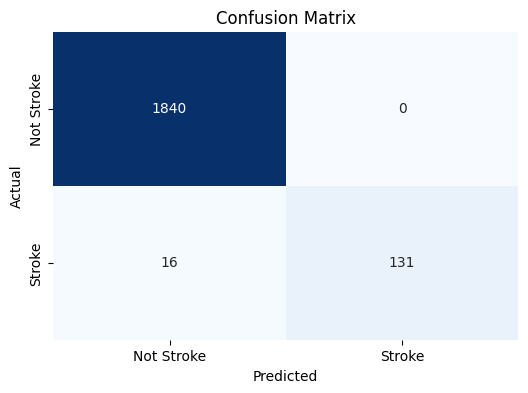


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      1.00      1.00      1840
      Stroke       1.00      0.89      0.94       147

    accuracy                           0.99      1987
   macro avg       1.00      0.95      0.97      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: 0.9992420881396037


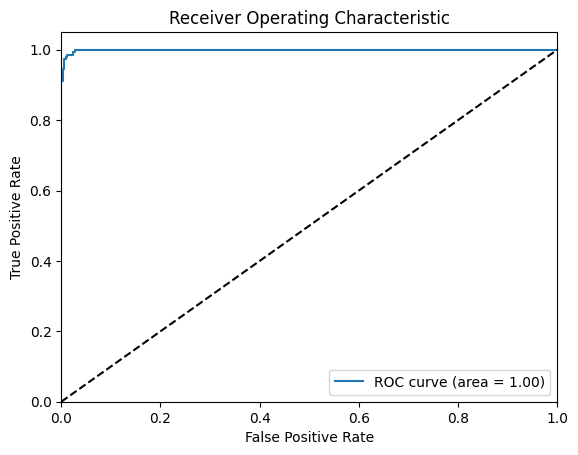

PR AUC: 0.991784244976962


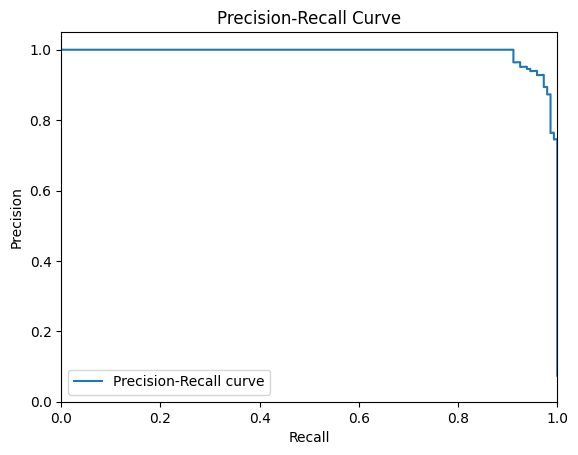

 38%|███▊      | 5/13 [00:04<00:05,  1.35it/s]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


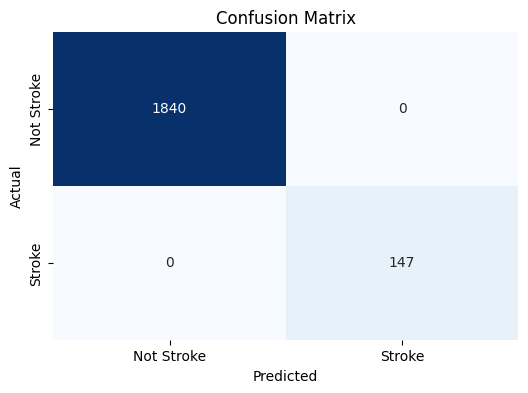


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


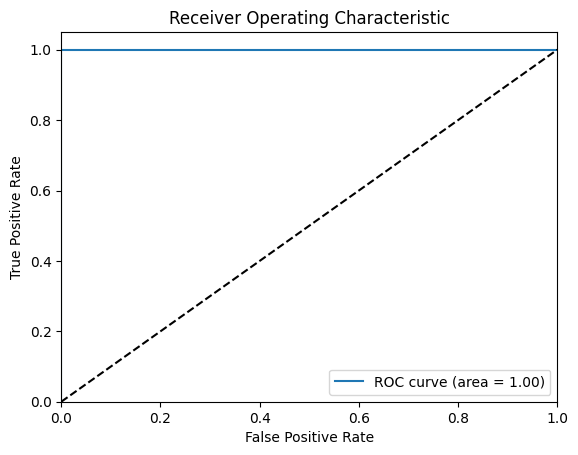

PR AUC: 1.0


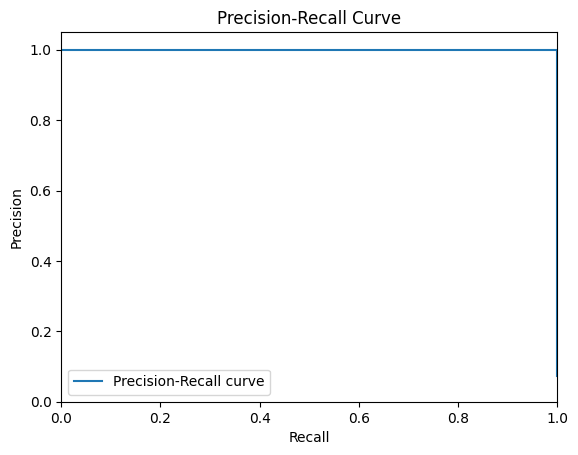

 46%|████▌     | 6/13 [00:04<00:05,  1.30it/s]


Confusion Matrix:
 [[1838    2]
 [  24  123]]


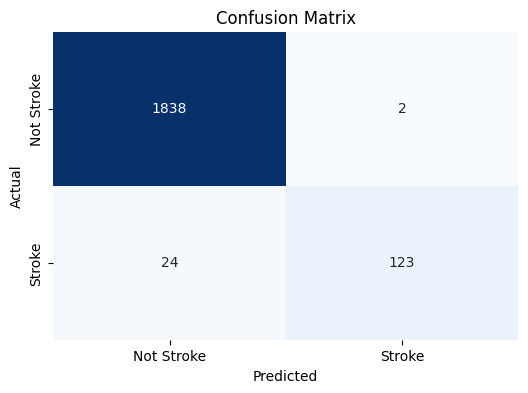


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      1.00      0.99      1840
      Stroke       0.98      0.84      0.90       147

    accuracy                           0.99      1987
   macro avg       0.99      0.92      0.95      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: 0.9993104850635907


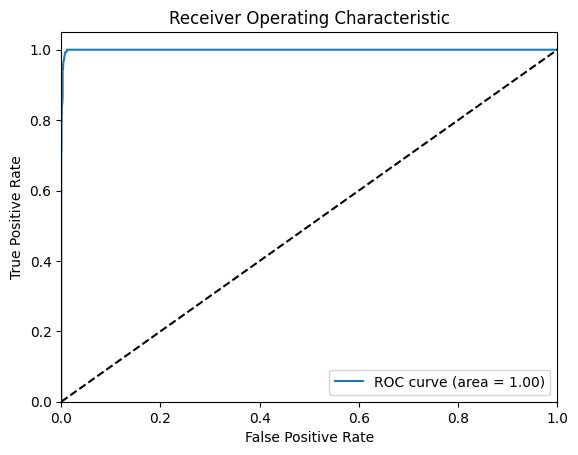

PR AUC: 0.9904857996155205


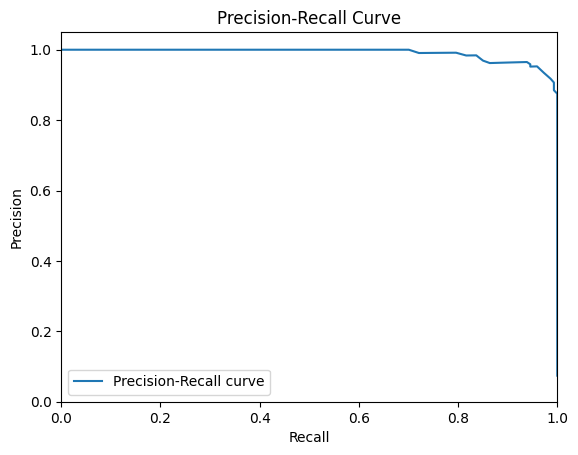

 54%|█████▍    | 7/13 [00:06<00:05,  1.11it/s]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


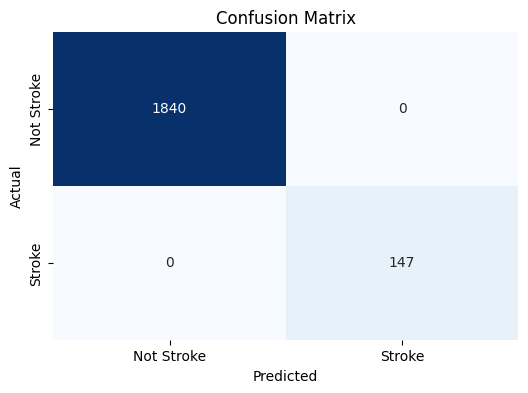


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


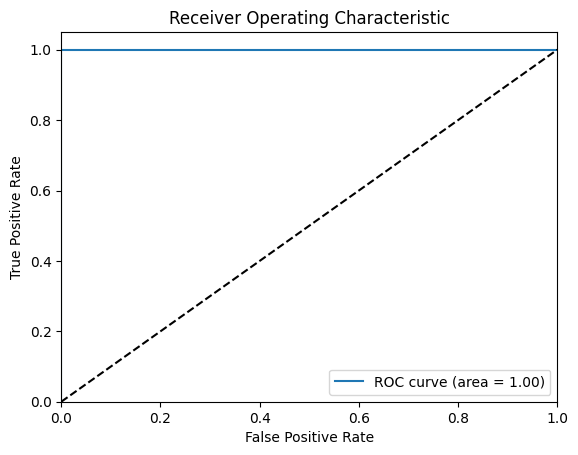

PR AUC: 1.0


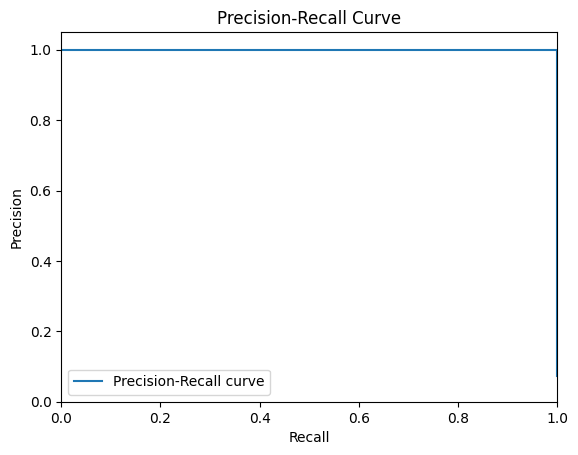

 62%|██████▏   | 8/13 [00:06<00:04,  1.09it/s]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


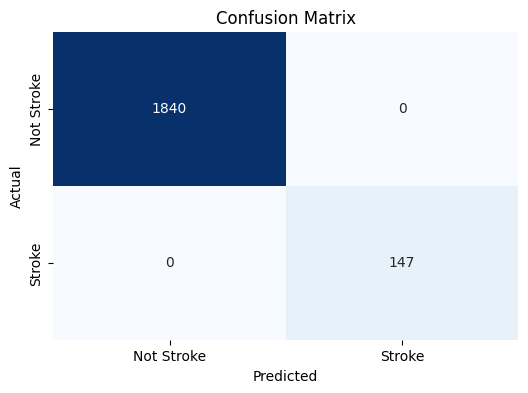


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


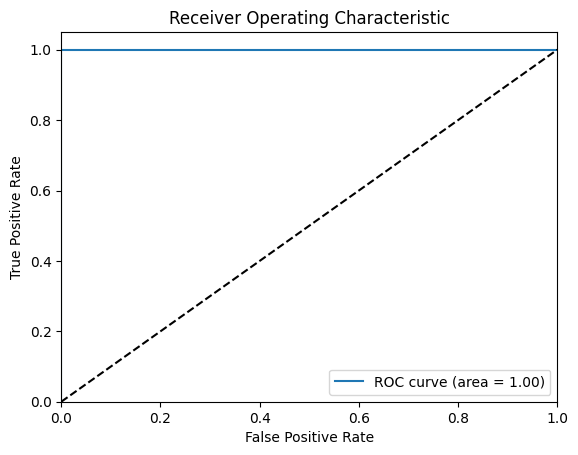

PR AUC: 1.0


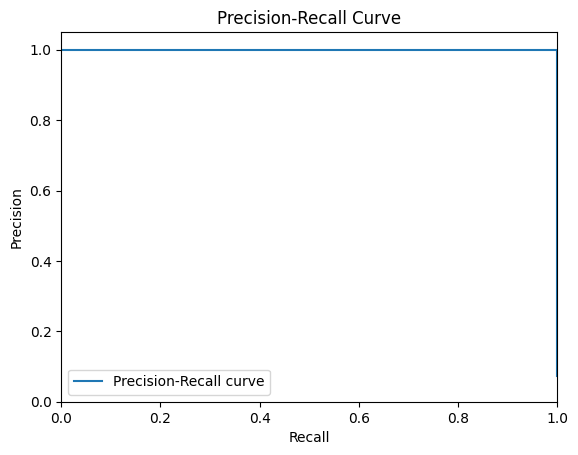

 69%|██████▉   | 9/13 [00:08<00:04,  1.03s/it]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


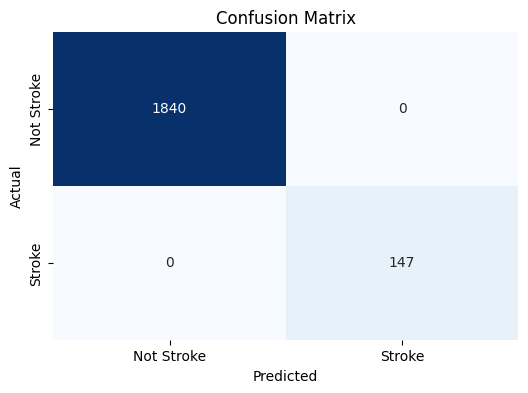


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


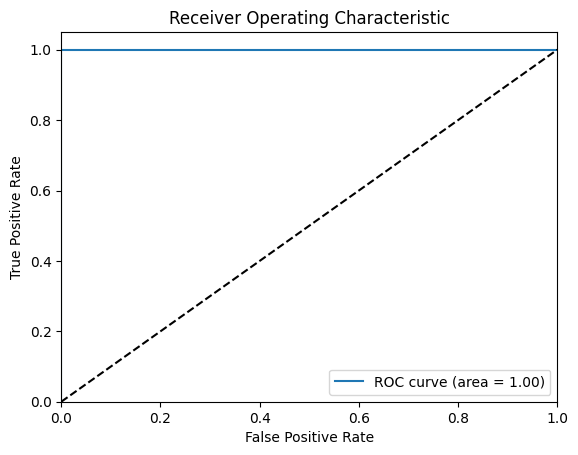

PR AUC: 1.0


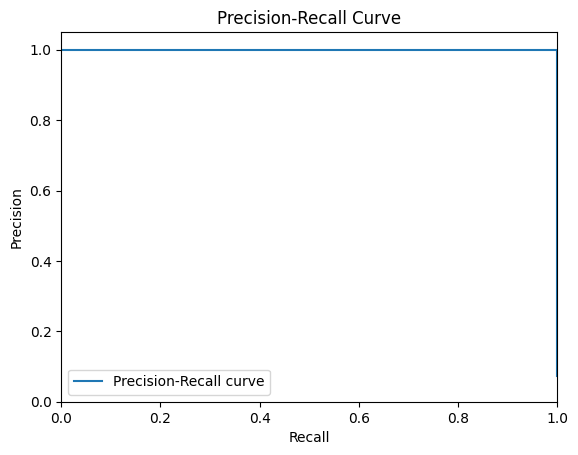

 77%|███████▋  | 10/13 [00:08<00:02,  1.09it/s]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:06:06] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1840    0]
 [   0  147]]


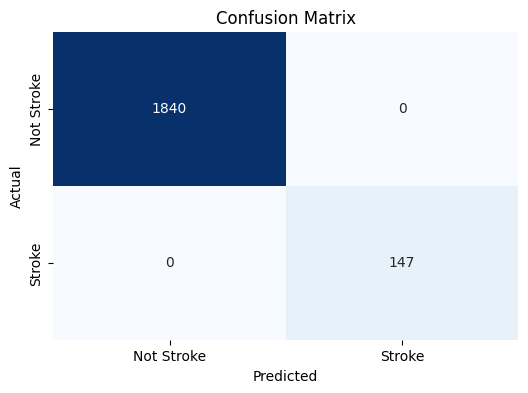


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


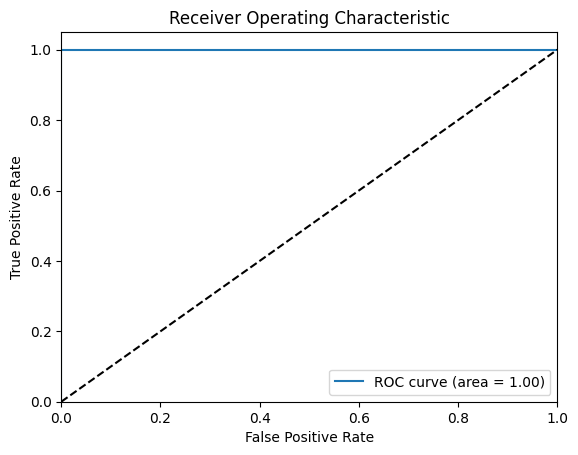

PR AUC: 1.0


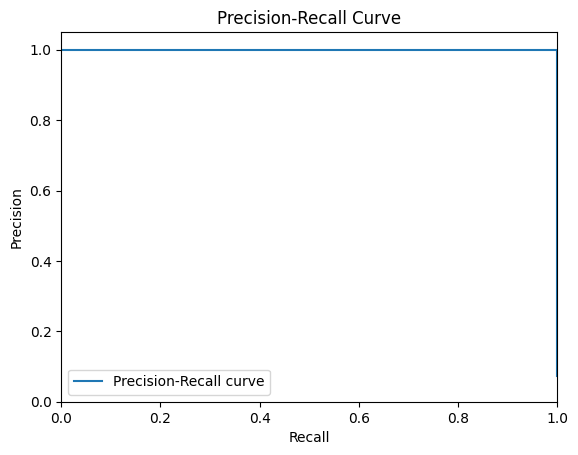

 85%|████████▍ | 11/13 [00:09<00:01,  1.26it/s]


Confusion Matrix:
 [[1840    0]
 [   0  147]]


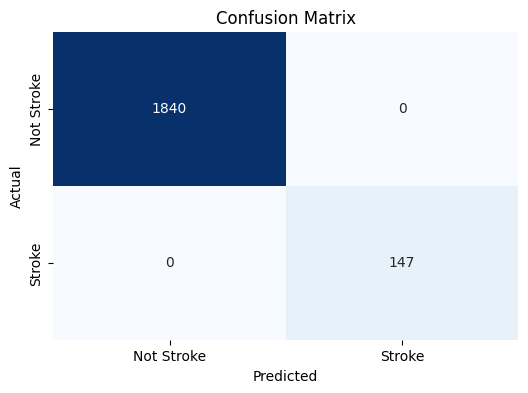


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


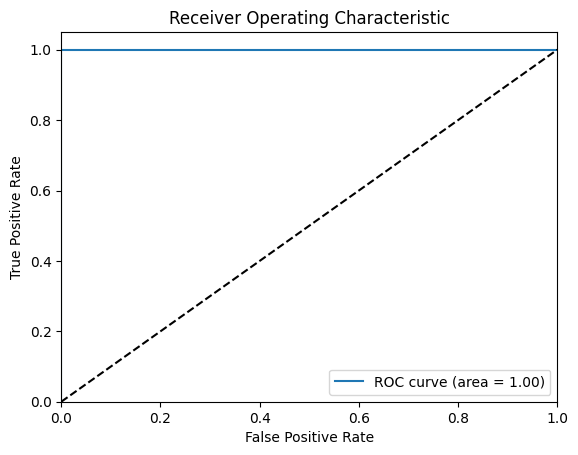

PR AUC: 1.0


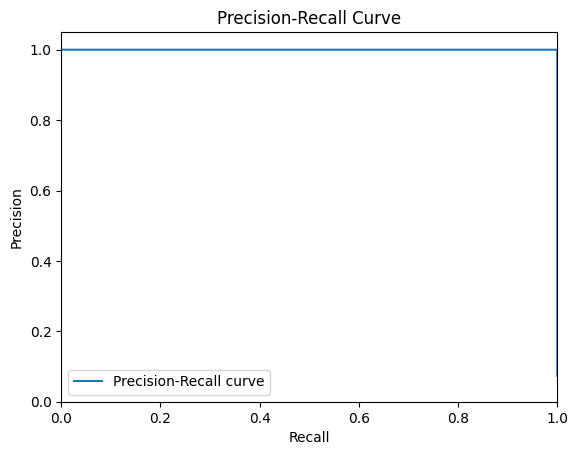

 92%|█████████▏| 12/13 [00:12<00:01,  1.55s/it]

[LightGBM] [Info] Number of positive: 702, number of negative: 7243
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000996 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 752
[LightGBM] [Info] Number of data points in the train set: 7945, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.088357 -> initscore=-2.333857
[LightGBM] [Info] Start training from score -2.333857
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

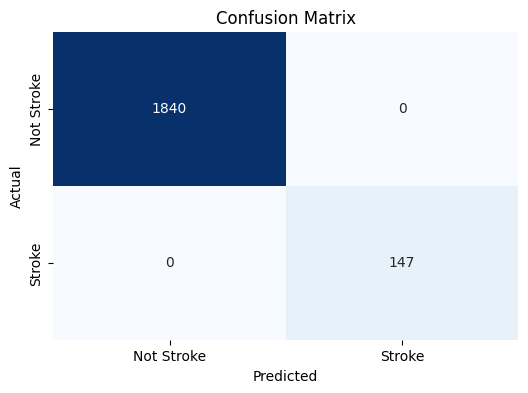


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


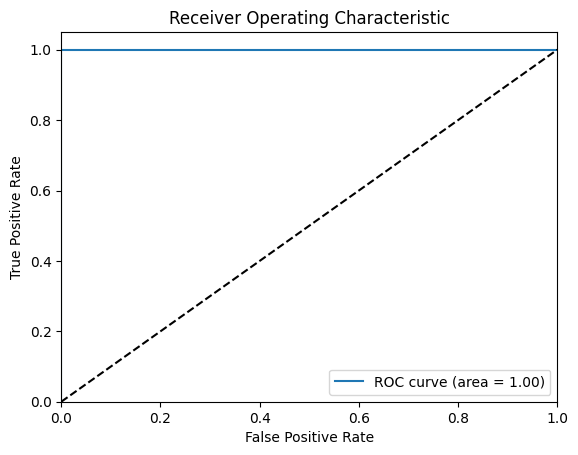

PR AUC: 1.0


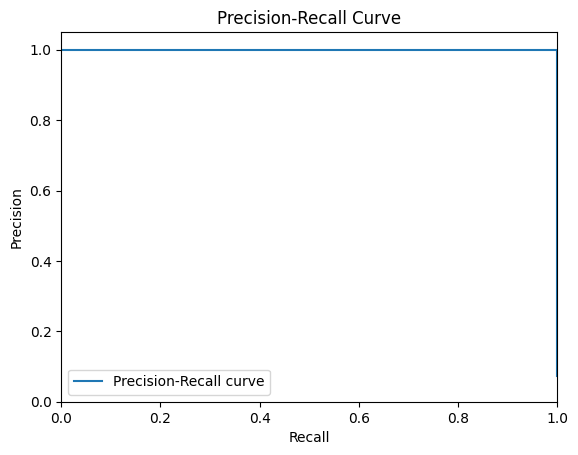

100%|██████████| 13/13 [00:13<00:00,  1.02s/it]


In [ ]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }



Confusion Matrix:
 [[1840    0]
 [   0  147]]


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:06:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


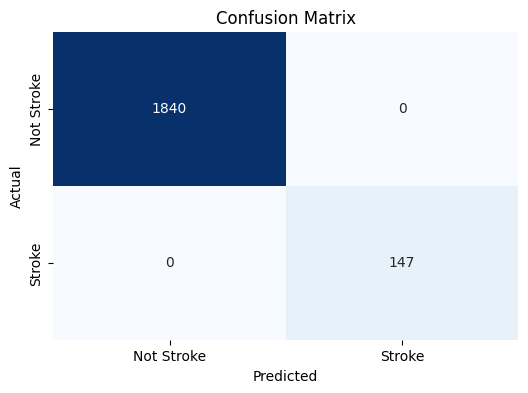


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


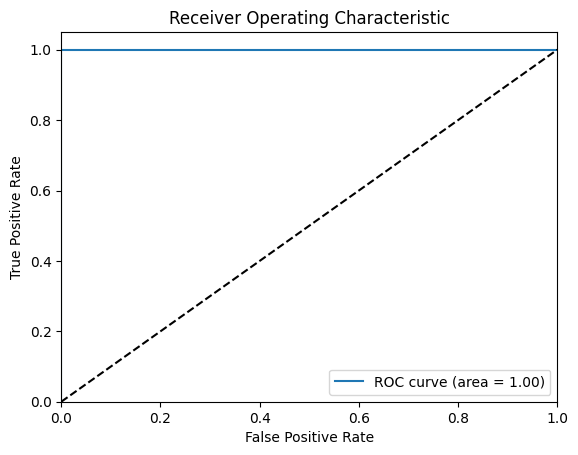

PR AUC: 1.0


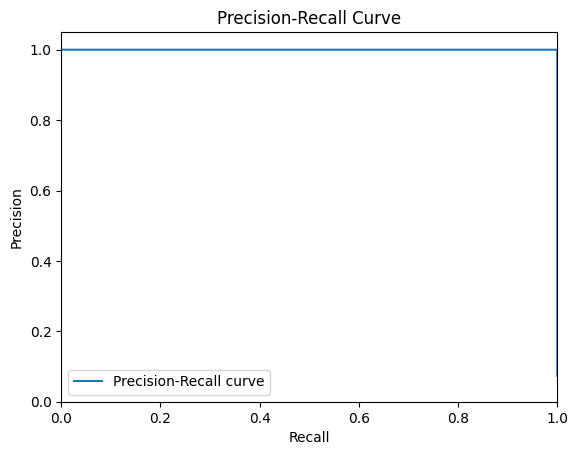

In [ ]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(x_train, y_train)
voting_train_pred = voting_model.predict(x_train)
voting_test_pred = voting_model.predict(x_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}


Confusion Matrix:
 [[1840    0]
 [   0  147]]


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:06:14] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


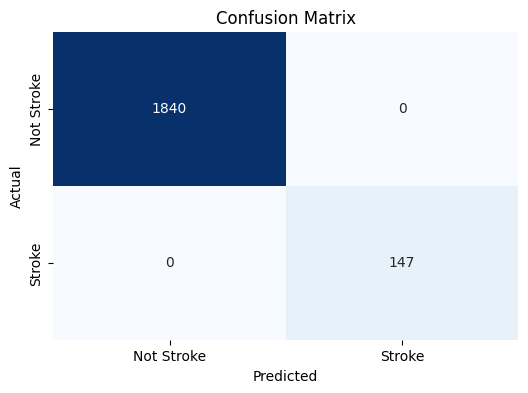


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1840
      Stroke       1.00      1.00      1.00       147

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


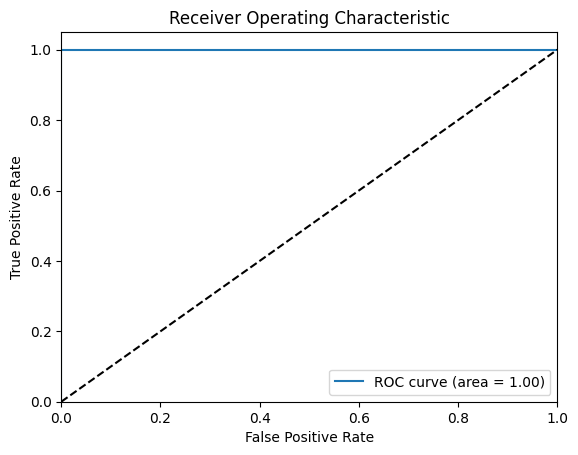

PR AUC: 1.0


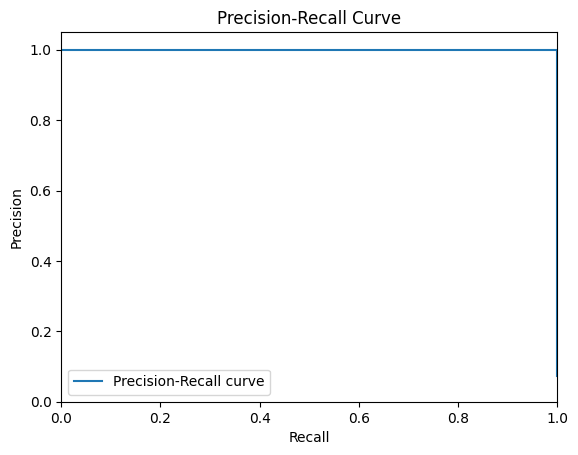

In [ ]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(x_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(x_train)
stack_auto_test_pred  = stack_auto.predict(x_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [ ]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Decision Tree,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Random Forest,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
CatBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
XGBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Hist Gradient Boosting,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Gradient Boosting,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
AdaBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Voting Classifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
LightGBM,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Stacking Classifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


<Axes: >

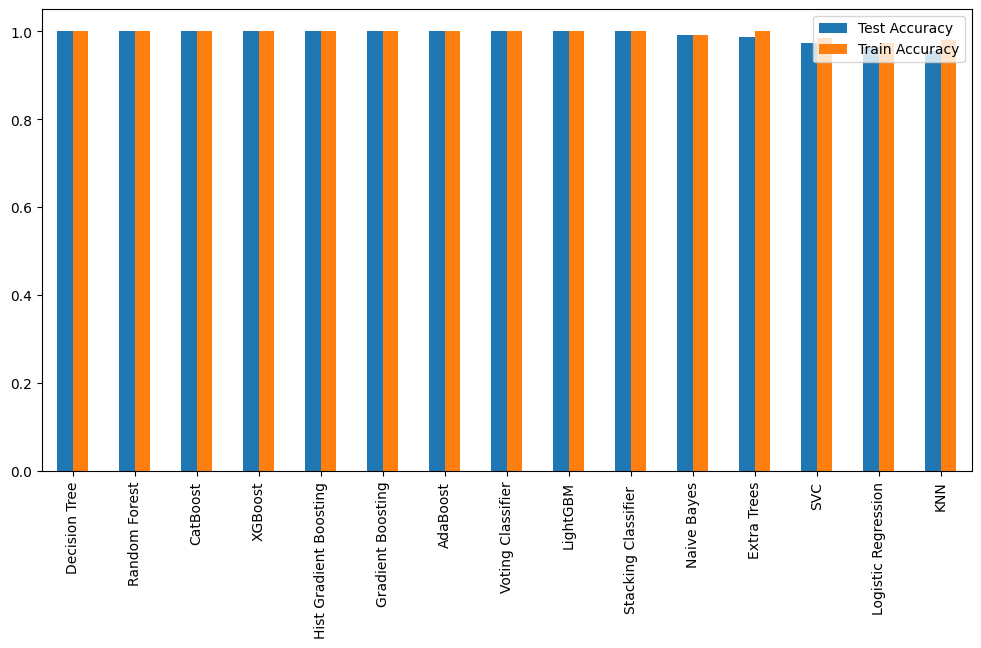

In [ ]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

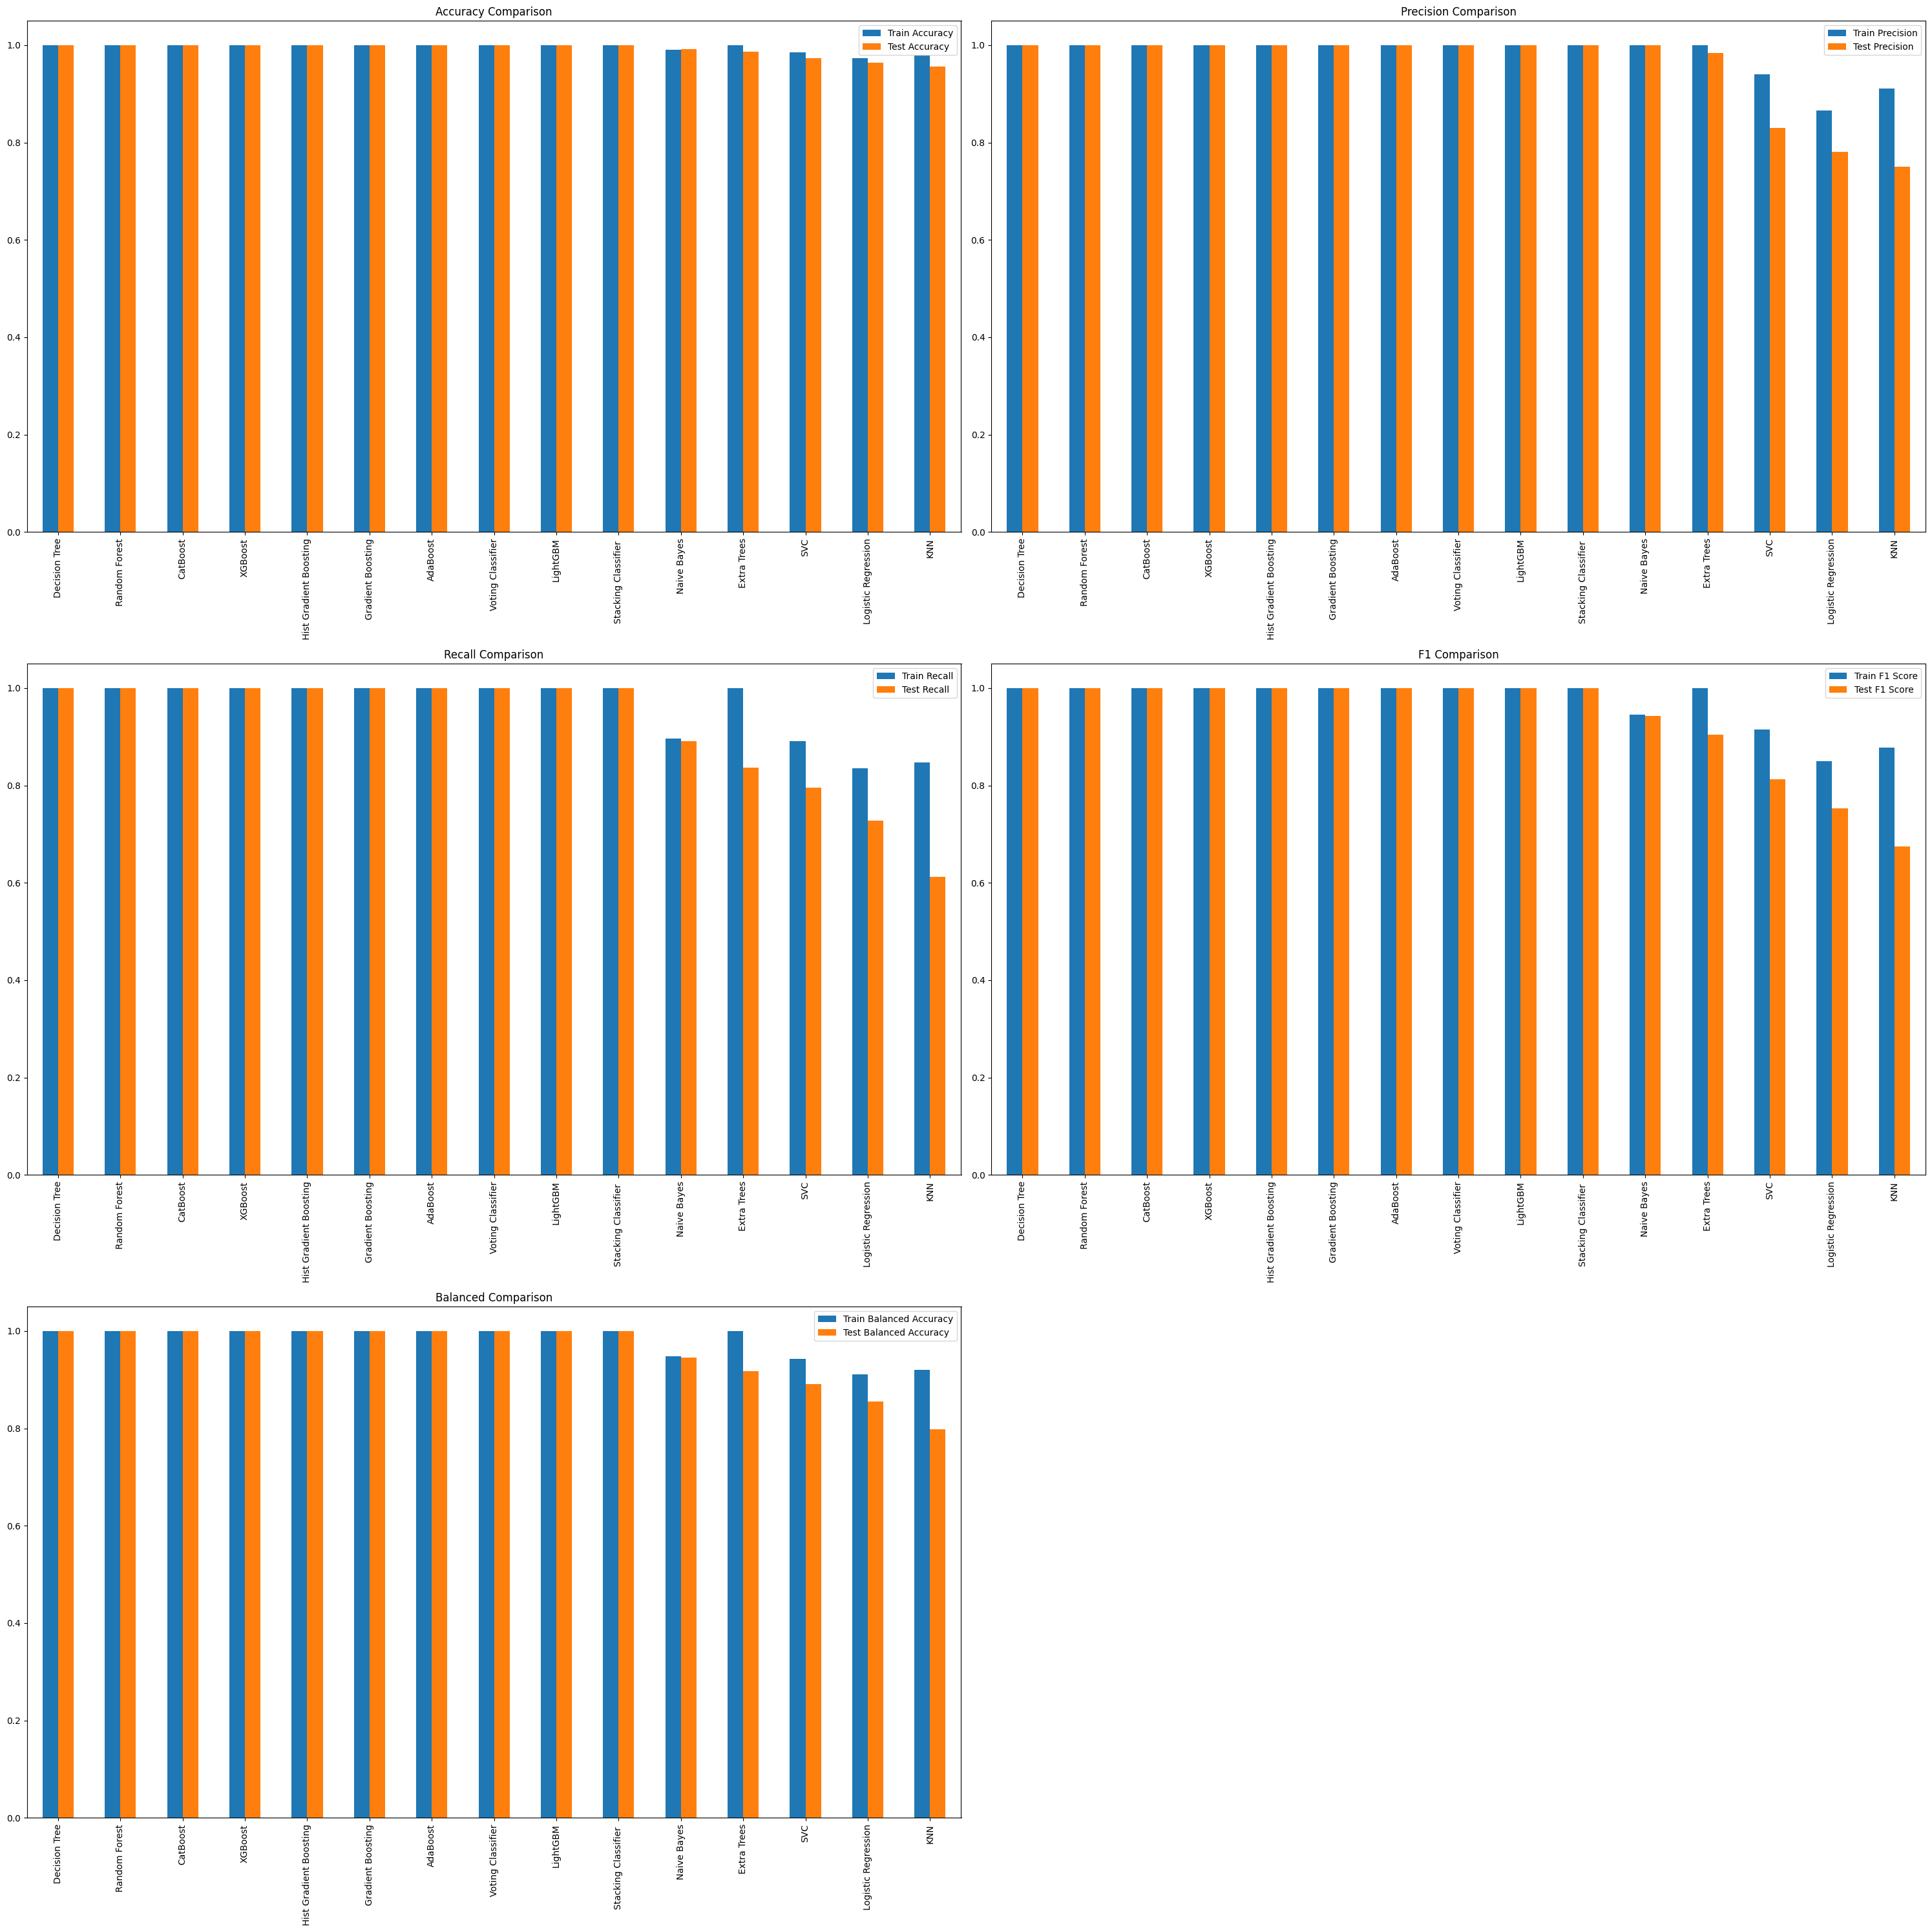

In [ ]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

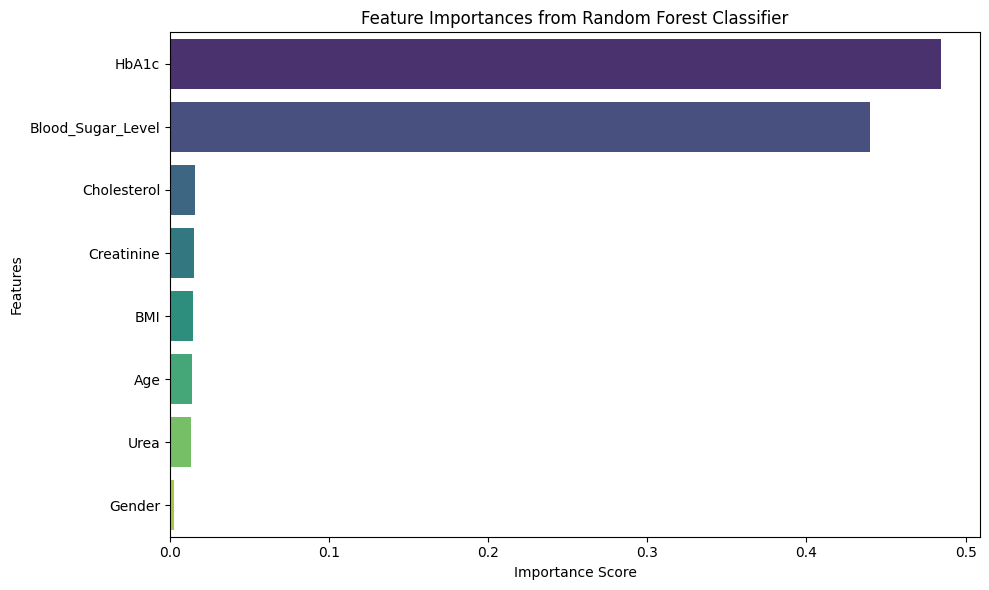

,Feature,Importance
7,HbA1c,0.484803
2,Blood_Sugar_Level,0.440206
6,Cholesterol,0.015475
3,Creatinine,0.015202
4,BMI,0.014603
0,Age,0.014101
5,Urea,0.013145
1,Gender,0.002465


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rf_model = models["Random Forest"]
rf_model.fit(x_train, y_train)

importances = rf_model.feature_importances_
feature_names = x_train.columns

fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=fi_df, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importances from Random Forest Classifier')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

display(fi_df)

In [ ]:
import gradio as gr
import numpy as np
import pandas as pd

# We will use our trained Random Forest model for real-time predictions
prediction_model = models["Random Forest"]

def predict_diabetes(age, gender, blood_sugar, creatinine, bmi, urea, cholesterol, hba1c):
    try:
        # Create a DataFrame with the exact columns and order as original x
        input_data = pd.DataFrame([{
            'Age': float(age),
            'Gender': gender,
            'Blood_Sugar_Level': float(blood_sugar),
            'Creatinine': float(creatinine),
            'BMI': float(bmi),
            'Urea': float(urea),
            'Cholesterol': float(cholesterol),
            'HbA1c': float(hba1c)
        }])

        # Encode categorical variable 'Gender' dynamically: 'Female' -> 0, 'Male' -> 1
        gender_map = {'Female': 0, 'Male': 1}
        input_data['Gender'] = input_data['Gender'].map(gender_map)

        # Standard scaler was fitted on individual columns.
        # To prevent feature name mismatch errors when transforming differently named columns,
        # we pass the column values as a raw numpy array to bypass pandas feature name checks.
        for col in input_data.columns:
            input_data[[col]] = scalar.transform(input_data[[col]].values)

        # Make prediction
        prediction_encoded = int(prediction_model.predict(input_data)[0])
        probabilities = prediction_model.predict_proba(input_data)[0]

        # Decode target variable prediction using target label encoder (le)
        prediction_class = str(le.inverse_transform([prediction_encoded])[0])

        # Prepare probabilities dictionary for Gradio output
        class_labels = le.classes_
        prob_dict = {str(class_labels[i]): float(probabilities[i]) for i in range(len(class_labels))}

        return prediction_class, prob_dict
    except Exception as e:
        return f"Error during prediction: {str(e)}", {}

# Define Gradio components
inputs = [
    gr.Slider(minimum=0, maximum=120, value=45, label="Age"),
    gr.Dropdown(choices=["Female", "Male"], value="Male", label="Gender"),
    gr.Slider(minimum=50, maximum=300, value=120, label="Blood Sugar Level"),
    gr.Slider(minimum=0.1, maximum=5.0, value=1.0, label="Creatinine"),
    gr.Slider(minimum=10.0, maximum=50.0, value=25.0, label="BMI"),
    gr.Slider(minimum=5.0, maximum=100.0, value=30.0, label="Urea"),
    gr.Slider(minimum=100, maximum=400, value=180, label="Cholesterol"),
    gr.Slider(minimum=3.0, maximum=15.0, value=5.5, label="HbA1c")
]

outputs = [
    gr.Textbox(label="Predicted Class"),
    gr.Label(num_top_classes=2, label="Prediction Probabilities")
]

# Create and launch Gradio Interface
demo = gr.Interface(
    fn=predict_diabetes,
    inputs=inputs,
    outputs=outputs,
    title="⚕️ Clinical Diabetes Predictor",
    description="Adjust the medical parameters below to predict the probability of a patient being diabetic using our optimized Random Forest model."
)

# Launch with inline display and shareable link enabled
demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://34721cdb0dc515eaa1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Created dataset file at: .gradio/flagged/dataset1.csv


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut